In [1]:
# ═════ 1 · SETTINGS ══════════════════════════════════════════════════════════════════════════════════════════════
# Blood age on MIMIC-IV v3.1. Every patient is split once into train / validation / test. An age model learns from NORMAL
# visits of training patients, is tested on other (normal) people, and is then applied to ABNORMAL people it has never seen
# to see how far their predicted age departs from their real age. Inputs follow the original age_prediction notebook
# (about 90 labs, "not measured" kept as information) plus each person's earlier blood results; the models are boosted
# trees and tabular neural networks (MLP, PLE-ResNet, TabM), combined by a stacked ensemble. Blood plus clinic body
# measurements from omr (blood pressure, BMI, weight, from the years before each visit); no diagnoses, no hospital-use
# counts. Normal vs abnormal comes from lab tests only (GROUP_SOURCE = "labs"), exactly as in the blood-only version.
# Kaggle: add the MIMIC-IV hosp tables patients, admissions, d_labitems, labevents and omr (.csv or .csv.gz) as input, set
# Accelerator = GPU, then Run All. This is the only cell with choices.
import json, os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import xgboost as xgb
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 70)

RUN_MODE = "FULL"           # "DEV" = a fixed 20 % of patients for a quick check (R2 lower: 5x fewer patients to learn
                           # from); "FULL" = every patient: use it for the numbers you report
SEED = 42
DATA_DIR = None            # None = the folder below /kaggle/input that holds patients.csv(.gz); set it if several do

# --- age label and blood panel (the original notebook's hospital setting)
AGE_MIN, AGE_MAX = 18, 89  # MIMIC-IV stores ages above 89 as 91: those patients are left out
ED_LOOKBACK_H = 24         # a panel window starts at ED arrival if that is at most 24 h before the admission ...
WINDOW_H = 24              # ... and ends 24 h after the admission
CORE_SHARE = 0.70          # core labs = labs in >= 70 % of the training pile's admission windows (as in the original)
PANEL_RULE = 0.70          # a full panel holds >= 70 % of the core labs; validation, test and compared visits are full
TRAIN_PANEL_RULE = 0.35    # training visits may also be PARTIAL panels (>= 35 % of the core labs) ...
TRAIN_PARTIAL = "auto"     # ... True / False, or "auto": cell 7 keeps them only if they improve validation (quick XGBoost)
SPLIT_SHARES = (0.70, 0.15, 0.15)   # EVERY patient, once: train / validation / test pile, within anchor-age band x sex

# --- who the model learns from (training pile). A NORMAL person has no abnormal result in any visit, ever.
ALL_VISITS = True          # every usable panel (admission) of a training person, not only the first
VISIT_WEIGHTS = "auto"     # "person": a person with k training visits gives each 1/k (every person counts once); "visit":
                           # every visit counts 1; "auto": cell 7 picks the one that predicts validation people better
TRAIN_ABNORMAL_BEFORE = True   # abnormal people of the TRAINING pile also give their visits that ended before their first
                               # abnormal result (abnormal people of the validation / test piles are never trained on)
TRAIN_UNTESTED = True      # labs mode: people never checked (no HbA1c) with no abnormal result are also learned from, from
                           # any pile: they are never validated, tested or compared, so train and test people never mix

# --- inputs (cell 6): the original notebook's inputs, plus calmer and earlier blood values of the same person. Every
#     input comes from the visit itself or from before it (no future values), and no input is derived from age.
LAB_SHARE = 0.02           # inputs = labs in >= 2 % of the training rows (the original used 5 %) ...
RARE_SHARE = 0.003         # ... and rarer labs (>= 0.3 %) as their window mean and earlier mean only (0 = none)
DERIVED_LABS = r"^eag$|^cholesterol ratio|non-?hdl"   # labs CALCULATED from a group-defining lab (eAG from HbA1c, total /
                           # HDL ratio from total cholesterol): never inputs, like the defining labs themselves
STATS = ("first", "last", "min", "max", "mean")   # per lab, inside the arrival window (the original used first, min, max)
DISCHARGE_H = 24           # + each lab's mean over the last 24 h before discharge: the recovered, calmer blood (0 = off)
HISTORY_YEARS = None       # + each lab's mean and last value BEFORE the visit and the change since: None = all earlier
                           # years (MIMIC covers ~14), a number = only that many years, 0 = off
HISTORY_TREND = True       # + each lab's trend per year over the earlier results (>= 3 results spanning >= 30 days)
RATIOS = {                 # + ratios of two input labs (window means); left out when a lab is not an input
    "BUN / creatinine": ("^urea nitrogen", "^creatinine"),
    "neutrophils / lymphocytes": ("^neutrophils", "^lymphocytes"),
    "monocytes / lymphocytes": ("^monocytes", "^lymphocytes"),
    "platelets / lymphocytes": ("^platelet count", "^lymphocytes"),
    "AST / ALT": ("^asparate aminotransferase|^aspartate aminotransferase", "^alanine aminotransferase"),
    "hemoglobin / RDW": ("^hemoglobin", "^rdw"),
}
HIDE_WHICH_TESTS = False   # False (the original's way): a lab not measured stays missing and the number of results drawn
                           # is an input, so the models also read WHICH tests were ordered (higher R2). True: hidden.
HIDDEN_CHECK = True        # robustness check: a second XGBoost (same settings) that cannot see which tests were ordered;
                           # the age-gap table shows every group's difference under both models (sick people get more
                           # tests, so a gap that shrinks a lot under the check partly reflects testing, not blood values)

# --- clinic body measurements (omr table: outpatient blood pressure, BMI, weight; dates, no times). Per kind, over the
#     VITALS_YEARS before each visit, dated on or before the visit's first day (never later): the last value, the mean of
#     the daily values and the trend per year (>= 3 days spanning >= 30 days). eGFR in omr is never used (its formula
#     contains age). Missing stays missing, like a lab not measured.
VITALS = ("blood pressure", "bmi", "weight")   # any of "blood pressure" (systolic, diastolic, pulse pressure), "bmi",
                                               # "weight", "height"; () = off (the blood-only notebook)
VITALS_YEARS = 3           # look-back in years before the visit (None = all earlier years)
BLOOD_ONLY_CHECK = True    # robustness check: the same XGBoost without the omr inputs (how much omr adds, and whether the
                           # age-gap results hold without it); not part of the ensemble

# --- the unit that is judged (cells 5, 8, 9)
PER_PERSON = True          # True: a validation / test / compared person's predicted age = the average over ALL their usable
                           # visits (less day-to-day noise); first-visit R2 is reported too. False: each person's first visit.

# --- models (cell 7)
MODELS = ["Ridge", "XGBoost", "LightGBM", "CatBoost", "Neural network (MLP)", "Neural network (PLE-ResNet)",
          "Neural network (TabM)"]
FULL = RUN_MODE == "FULL"
N_CONFIGS = 30 if FULL else 6          # XGBoost settings tried at most (random search: depth 7 up to a cap that fits the
                                       # GPU memory, about 10 with ~900 inputs, or leaf-wise trees)
LGB_CONFIGS = 4 if FULL else 2         # LightGBM settings tried at most
CAT_DEPTHS = (8, 10)                   # CatBoost tree depths tried
BAG_SEEDS = 4 if FULL else 1           # the best XGBoost and LightGBM settings are trained with this many seeds, averaged
MINUTES = {"XGBoost": 75, "LightGBM": 50, "CatBoost": 25, "Neural network (MLP)": 10,
           "Neural network (PLE-ResNet)": 30, "Neural network (TabM)": 50}
if not FULL:
    MINUTES = {m: max(3, v // 6) for m, v in MINUTES.items()}
                               # time cap of each model in minutes (search + extra seeds): with the data cells and the
                               # checks a FULL run takes about 5 h on a Kaggle T4 GPU (Kaggle stops a run at 12 h). A model
                               # always finishes its first settings; a training already started is not cut.
DNN = dict(layers=(512, 256, 128), dropout=0.15, lr=1e-3, weight_decay=1e-4, batch=512, max_epochs=300, patience=15,
           seeds=3)            # the MLP (PyTorch, GPU when present): 3 nets with different seeds, averaged
PLE_NET = dict(configs=4 if FULL else 2, seeds=5 if FULL else 2, bins=8, batch=1024, max_epochs=200, patience=12)
                               # PLE-ResNet: piecewise-linear encoding of every input + residual blocks (Gorishniy et al.
                               # 2021, 2022); a few settings tried on validation, the best one trained with several seeds
TABM = dict(configs=3 if FULL else 2, seeds=2 if FULL else 1, k=32, bins=8, batch=512, max_epochs=120, patience=10)
                               # TabM (Gorishniy et al., ICLR 2025): k=32 sub-networks sharing one MLP (parameter-
                               # efficient ensembling), plain or with piecewise-linear embeddings; best setting + seeds
BOOT = 1000                # bootstrap resamples for the 95 % intervals

# --- what makes a result abnormal: lab tests ("labs"), diagnosis codes ("diagnoses"), or "auto" (diagnosis codes when
#     diagnoses_icd is in the input, else lab tests). A visit is NORMAL when the whole stay ended before the person's first
#     abnormal result (labs) or came before their first coded admission (diagnoses); a visit taken during a severe acute
#     illness is used for nothing (it does not make the person abnormal).
GROUP_SOURCE = "labs"      # "labs", "diagnoses" or "auto". Kept at "labs", the blood-only run's definition: with
                           # diagnoses_icd in the input, "auto" would switch to diagnosis codes (other normal people)

# (a) labs: a result meeting a rule marks the person from that moment on (results at any time, inpatient or outpatient).
#     These labs are never model inputs, so the groups are not defined by the inputs themselves. A NORMAL person has no
#     rule met at any time and at least one result of LAB_NORMAL_NEEDS (checked); people never checked, with no rule met,
#     are learned from only (TRAIN_UNTESTED). A panel window with LAB_ACUTE met is used for nothing (severe acute illness).
LAB_DISEASES = {           # group: rules (lab-name pattern, test, value); "not_if" = not counted when that group is present
    "Diabetes (HbA1c >= 6.5 %)":           {"rules": [("a1c", ">=", 6.5)]},
    "Prediabetes (HbA1c 5.7-6.4 %)":       {"rules": [("a1c", "between", (5.7, 6.5))], "not_if": "Diabetes (HbA1c >= 6.5 %)"},
    "High LDL / cholesterol / TG":         {"rules": [("ldl", ">=", 160), ("^cholesterol, total$", ">=", 240),
                                                      ("^triglycerides$", ">=", 200)]},
    "Thyroid disease (TSH < 0.1 or > 10)": {"rules": [("thyroid stimulating hormone", "<", 0.1),
                                                      ("thyroid stimulating hormone", ">", 10)]},
    "Heart strain (NT-proBNP >= 1800)":    {"rules": [("ntprobnp", ">=", 1800)]},
}
LAB_NORMAL_NEEDS = "a1c"                   # normal = HbA1c measured at least once, and every result below the rules
LAB_ACUTE = ("^lactate$", ">=", 4.0)       # lactate >= 4 mmol/L in the panel window = severe acute illness

# (b) diagnoses_icd: ICD-9 / ICD-10 codes matched by their start (MIMIC stores them without dots; "not" = starts left
#     out). Abnormal = coded at the panel's admission or an earlier one; normal = none coded at any admission.
DISEASES = {
    "Diabetes":         {"icd10": ["E08", "E09", "E10", "E11", "E13"], "icd9": ["250"]},
    "Kidney disease":   {"icd10": ["N18", "I12", "I13", "Z49", "Z992"], "icd9": ["585", "403", "404", "V451", "V56"]},
    "Heart failure":    {"icd10": ["I50", "I110", "I130", "I132"],
                         "icd9": ["428", "40201", "40211", "40291", "40401", "40403", "40411", "40413", "40491", "40493"]},
    "Coronary disease": {"icd10": ["I20", "I21", "I22", "I23", "I24", "I25"], "icd9": ["410", "411", "412", "413", "414"]},
    "Stroke":           {"icd10": ["I6", "G45"], "icd9": ["430", "431", "432", "433", "434", "435", "436", "437", "438"]},
    "COPD":             {"icd10": ["J41", "J42", "J43", "J44", "J47"], "icd9": ["491", "492", "494", "496"]},
    "Liver disease":    {"icd10": ["K70", "K73", "K74", "K76", "B18"],
                         "icd9": ["571", "07022", "07023", "07032", "07033", "07044", "07054"]},
    "Cancer":           {"icd10": ["C"], "icd9": ["14", "15", "16", "17", "18", "19", "200", "201", "202", "203", "204",
                                                   "205", "206", "207", "208"], "not": ["C44", "173"]},   # not skin (non-melanoma)
    "Dementia":         {"icd10": ["F01", "F02", "F03", "G30"], "icd9": ["290", "2941", "3310", "3311", "3312"]},
    "HIV":              {"icd10": ["B20", "Z21"], "icd9": ["042", "V08"]},
    # "Hypertension":   {"icd10": ["I10", "I11", "I15", "I16"], "icd9": ["401", "402", "405"]},   # remove the # to add it
}
ACUTE = {"icd10": ["A40", "A41", "R652", "R57", "N17", "J960", "J962", "I46"],   # sepsis, shock, acute kidney injury,
         "icd9": ["038", "99591", "99592", "7855", "584", "51881", "51884", "4275"]}   # acute respiratory failure, arrest

# --- where things are (found on their own on Kaggle)
DEV_SHARE = 0.20
INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
if DATA_DIR is None:
    assert INPUT.is_dir(), "Not on Kaggle: set DATA_DIR in this cell to the folder with the MIMIC-IV hosp tables."
    homes = sorted({p.parent for p in INPUT.rglob("patients.csv*") if p.name in ("patients.csv", "patients.csv.gz")})
    assert len(homes) == 1, f"Set DATA_DIR in this cell: patients.csv found in {[str(h) for h in homes] or 'no folder'}"
    DATA_DIR = homes[0]
DATA_DIR = Path(DATA_DIR)


def find_table(name):
    """name.csv or name.csv.gz in DATA_DIR, else anywhere below /kaggle/input (e.g. diagnoses_icd added as its own dataset)."""
    for folder in [DATA_DIR] + ([INPUT] if INPUT.is_dir() else []):
        hits = sorted(p for p in folder.rglob(f"{name}.csv*") if p.name in (f"{name}.csv", f"{name}.csv.gz"))
        if hits:
            return hits[0]
    return None


TABLES = {t: find_table(t) for t in ["patients", "admissions", "d_labitems", "labevents", "diagnoses_icd", "omr"]}
missing = [t for t in ["patients", "admissions", "d_labitems", "labevents"] if TABLES[t] is None]
assert not missing, f"Missing MIMIC-IV hosp table(s): {missing}"
assert GROUP_SOURCE in ("auto", "labs", "diagnoses"), f"GROUP_SOURCE must be auto, labs or diagnoses, not {GROUP_SOURCE!r}"
SOURCE = "diagnoses" if GROUP_SOURCE == "diagnoses" or (GROUP_SOURCE == "auto" and TABLES["diagnoses_icd"]) else "labs"
assert SOURCE == "labs" or TABLES["diagnoses_icd"], "GROUP_SOURCE = 'diagnoses' needs diagnoses_icd.csv(.gz) in the input."
unknown_ = set(VITALS) - {"blood pressure", "bmi", "weight", "height"}
assert not unknown_, f"VITALS: unknown kind(s) {sorted(unknown_)}; use blood pressure, bmi, weight or height."
USE_VITALS = bool(VITALS) and TABLES["omr"] is not None
OUT = WORK / "age_gap"
OUT.mkdir(parents=True, exist_ok=True)
TMP = Path("/tmp/age_gap")
TMP.mkdir(parents=True, exist_ok=True)
old_cache = [p for p in [WORK / "age_prediction" / "labevents_slim.parquet", OUT / "labevents_slim.parquet"] if p.exists()]
if not old_cache and INPUT.is_dir():
    old_cache = sorted(INPUT.rglob("labevents_slim.parquet"))       # the main notebook's lab cache, if attached as input
LAB_CACHE = old_cache[0] if old_cache else OUT / "labevents_slim.parquet"
THREADS = os.cpu_count() or 4
try:
    import psutil
    MEM_GB = max(2, int(0.6 * psutil.virtual_memory().available / 1e9))
except ImportError:
    MEM_GB = 8
with warnings.catch_warnings():                 # XGBoost silently falls back to the CPU when no GPU is usable
    warnings.simplefilter("ignore")
    try:
        _probe = xgb.train({"device": "cuda", "tree_method": "hist", "verbosity": 0},
                           xgb.DMatrix(np.random.rand(64, 4), label=np.random.rand(64)), 2)
        DEVICE = "cuda" if json.loads(_probe.save_config())["learner"]["generic_param"]["device"].startswith("cuda") else "cpu"
    except Exception:
        DEVICE = "cpu"
SOURCE_TXT = ("diagnosis codes (diagnoses_icd)" if SOURCE == "diagnoses" else "lab tests"
              + (" (diagnoses_icd in the input but not used: GROUP_SOURCE = 'labs')" if TABLES["diagnoses_icd"]
                 else " (no diagnoses_icd in the input)"))
VITALS_TXT = (", ".join(VITALS) + (f", {VITALS_YEARS} y before each visit" if VITALS_YEARS is not None
                                   else ", all years before each visit") if USE_VITALS
              else "not used" + ("" if TABLES["omr"] or not VITALS else " (NO omr IN THE INPUT: add omr.csv(.gz) to use them)"))
print(f"RUN_MODE {RUN_MODE} | data: {DATA_DIR} | normal vs abnormal from: {SOURCE_TXT} | body measurements (omr): "
      f"{VITALS_TXT} | GPU: {DEVICE == 'cuda'} | {THREADS} CPU threads, DuckDB memory {MEM_GB} GB | lab cache: "
      + (f"reused ({LAB_CACHE})" if LAB_CACHE.exists() else "built in cell 2 (about 5-15 min, once per session)"))

RUN_MODE FULL | data: /kaggle/input/datasets/youssefmoghareeb/aging-data/AGING | normal vs abnormal from: lab tests (diagnoses_icd in the input but not used: GROUP_SOURCE = 'labs') | body measurements (omr): blood pressure, bmi, weight, 3 y before each visit | GPU: True | 4 CPU threads, DuckDB memory 19 GB | lab cache: built in cell 2 (about 5-15 min, once per session)


In [2]:
# ═════ 2 · DATA: MIMIC-IV v3.1, hosp module ══════════════════════════════════════════════════════════════════════
# Beth Israel Deaconess Medical Center (Boston), admissions 2008-2022; every patient's dates are shifted into 2100-2200,
# so only intervals and ages are real. Blood labs are copied once from labevents into a slim Parquet file, then reused.
# omr (clinic blood pressure, BMI, weight) becomes the DuckDB table `vitals`: one row per usable value (subject, date,
# kind, value), values outside a plausible range dropped as entry errors; eGFR is never read (its formula contains age).
T0 = time.time()
con = duckdb.connect()
con.execute(f"SET threads={THREADS}; SET memory_limit='{MEM_GB}GB'; SET temp_directory='{TMP.as_posix()}'; "
            "SET preserve_insertion_order=false").fetchall()
patients = pd.read_csv(TABLES["patients"], usecols=["subject_id", "gender", "anchor_age", "anchor_year", "anchor_year_group"])
admissions = pd.read_csv(TABLES["admissions"], usecols=["subject_id", "hadm_id", "admittime", "dischtime", "edregtime",
                                                       "admission_type"], parse_dates=["admittime", "dischtime", "edregtime"])
labitems = pd.read_csv(TABLES["d_labitems"], usecols=["itemid", "label", "fluid", "category"])
diagnoses = (pd.read_csv(TABLES["diagnoses_icd"], usecols=["subject_id", "hadm_id", "icd_code", "icd_version"],
                         dtype={"icd_code": str}) if SOURCE == "diagnoses" else None)
is_blood = labitems.fluid.astype(str).str.strip().str.lower().eq("blood")
BANNED = r"\bgfr\b|egfr|mdrd|ckd-epi|\bage\b|fib-?4|cockcroft|estimated creatinine clearance|^stx[1-6]$"
# eGFR, FIB-4 and estimated creatinine clearance are computed from age (a leak); STX = analyser fields
CENSORED = r"^\s*[<>]=?\s*([0-9]*\.?[0-9]+)\s*$"                # '<0.01', '>60' -> the number
banned = is_blood & labitems.label.astype(str).str.strip().str.lower().str.contains(BANNED, regex=True)
blood = labitems.loc[is_blood & ~banned, ["itemid", "label", "category"]].reset_index(drop=True)

if not LAB_CACHE.exists():                                     # one pass over labevents: blood rows only
    t1 = time.time()
    con.register("blood_codes", labitems.loc[is_blood, ["itemid"]])
    part = LAB_CACHE.with_name(LAB_CACHE.name + ".part")
    con.execute(f"""
      COPY (SELECT TRY_CAST(subject_id AS INTEGER) AS subject_id, TRY_CAST(hadm_id AS INTEGER) AS hadm_id,
                   TRY_CAST(itemid AS INTEGER) AS itemid, TRY_CAST(charttime AS TIMESTAMP) AS charttime,
                   NULLIF(TRIM(value), '') AS value, TRY_CAST(valuenum AS DOUBLE) AS valuenum,
                   NULLIF(TRIM(valueuom), '') AS valueuom
            FROM read_csv('{TABLES["labevents"].as_posix()}', header=true, all_varchar=true)
            WHERE TRY_CAST(itemid AS INTEGER) IN (SELECT itemid FROM blood_codes))
      TO '{part.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)""").fetchall()
    os.replace(part, LAB_CACHE)
    con.unregister("blood_codes")
    print(f"Lab cache built in {(time.time() - t1) / 60:.1f} min: {LAB_CACHE}")
LABS_SQL = f"read_parquet('{LAB_CACHE.as_posix()}')"
n_lab, n_lab_patients = con.execute(f"SELECT count(*), count(DISTINCT subject_id) FROM {LABS_SQL}").fetchall()[0]

# omr: blood pressure '120/80' -> systolic, diastolic and pulse pressure (mmHg; every posture); BMI (kg/m2), weight (lb)
# and height (inch) as numbers. Plausible ranges: systolic 60-260 above diastolic 30-160, BMI 10-80, weight 60-700 lb,
# height 48-90 inch.
VITAL_KINDS, VITAL_UNITS = [], {"systolic BP": "mmHg", "diastolic BP": "mmHg", "pulse pressure": "mmHg", "BMI": "kg/m2",
                                "weight": "lb", "height": "inch"}
if USE_VITALS:
    BP_RE = r"^\s*(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)\s*$"
    con.execute(f"""
      CREATE OR REPLACE TEMP TABLE omr_raw AS
      SELECT TRY_CAST(subject_id AS BIGINT) AS subject_id, TRY_CAST(chartdate AS DATE) AS date,
             lower(trim(result_name)) AS name, trim(result_value) AS value
      FROM read_csv('{TABLES["omr"].as_posix()}', header=true, all_varchar=true)""").fetchall()
    sel_, kinds_ = [], []
    if "blood pressure" in VITALS:
        kinds_ += ["systolic BP", "diastolic BP", "pulse pressure"]
        sel_ += ["SELECT subject_id, date, 'systolic BP' AS kind, s AS v FROM bp",
                 "SELECT subject_id, date, 'diastolic BP' AS kind, d AS v FROM bp",
                 "SELECT subject_id, date, 'pulse pressure' AS kind, s - d AS v FROM bp"]
    for key_, (kind_, lo_v, hi_v) in {"bmi": ("BMI", 10, 80), "weight": ("weight", 60, 700),
                                      "height": ("height", 48, 90)}.items():
        if key_ in VITALS:
            kinds_.append(kind_)
            sel_.append(f"SELECT subject_id, date, '{kind_}' AS kind, x AS v FROM (SELECT subject_id, date, "
                        f"TRY_CAST(value AS DOUBLE) AS x FROM o WHERE starts_with(name, '{key_}')) WHERE x BETWEEN {lo_v} AND {hi_v}")
    con.execute(f"""
      CREATE OR REPLACE TEMP TABLE vitals AS
      WITH o AS (SELECT * FROM omr_raw WHERE subject_id IS NOT NULL AND date IS NOT NULL),
           bp AS (SELECT * FROM (SELECT subject_id, date, TRY_CAST(regexp_extract(value, '{BP_RE}', 1) AS DOUBLE) AS s,
                                        TRY_CAST(regexp_extract(value, '{BP_RE}', 2) AS DOUBLE) AS d
                                 FROM o WHERE starts_with(name, 'blood pressure'))
                  WHERE s BETWEEN 60 AND 260 AND d BETWEEN 30 AND 160 AND s > d)
      {' UNION ALL '.join(sel_)}""").fetchall()
    n_omr, n_egfr = con.execute("SELECT count(*), count(*) FILTER (WHERE name LIKE '%egfr%') FROM omr_raw").fetchall()[0]
    con.execute("DROP TABLE omr_raw").fetchall()
    n_vit = con.execute("SELECT kind, count(*) AS n FROM vitals GROUP BY kind").df().set_index("kind").n
    VITAL_KINDS = [k_ for k_ in kinds_ if n_vit.get(k_, 0) > 0]          # kinds with at least one usable value
    n_vit_people = con.execute("SELECT count(DISTINCT subject_id) FROM vitals").fetchall()[0][0]

# the dataset in numbers (all patients, before the DEV sample)
T_DATA = pd.DataFrame([
    ("patients", f"{len(patients):,}", f"female {100 * (patients.gender == 'F').mean():.1f} %; anchor_age mean "
     f"{patients.anchor_age.mean():.1f} (SD {patients.anchor_age.std():.1f}); {int((patients.anchor_age >= 91).sum()):,} "
     f"({100 * (patients.anchor_age >= 91).mean():.1f} %) older than 89, stored as 91 (left out)"),
    ("admissions", f"{len(admissions):,}", f"{admissions.subject_id.nunique():,} patients with at least one admission; "
     f"{100 * admissions.edregtime.notna().mean():.1f} % came through the emergency department"),
    ("d_labitems", f"{len(labitems):,}", f"{int(is_blood.sum())} blood lab codes, {int(banned.sum())} left out "
     f"(scores whose formula contains age, such as eGFR)"),
    ("labevents (blood rows)", f"{n_lab:,}", f"{n_lab_patients:,} patients with at least one blood result"),
    ("anchor_year_group", "", "; ".join(f"{k}: {v:,}" for k, v in patients.anchor_year_group.value_counts().sort_index().items())),
], columns=["table", "rows", "what it holds"])
if diagnoses is not None:
    per_adm, ver = diagnoses.groupby("hadm_id").size(), pd.to_numeric(diagnoses.icd_version, errors="coerce")
    T_DATA.loc[len(T_DATA)] = ("diagnoses_icd", f"{len(diagnoses):,}", f"ICD-9 {100 * (ver == 9).mean():.1f} % / ICD-10 "
                               f"{100 * (ver == 10).mean():.1f} %; median {per_adm.median():.0f} codes per admission")
if USE_VITALS:
    T_DATA.loc[len(T_DATA)] = ("omr", f"{n_omr:,}", f"{n_vit_people:,} patients with a usable value; "
                               + ", ".join(f"{k_} {int(n_vit.get(k_, 0)):,}" for k_ in kinds_)
                               + f" values; eGFR ({n_egfr:,} rows) never used: its formula contains age")
print("T1 - the dataset")
display(T_DATA)

if RUN_MODE == "DEV":                                          # the same fixed patients on every DEV run
    patients = patients.sort_values("subject_id").reset_index(drop=True)
    keep = patients.subject_id[np.random.default_rng(SEED).random(len(patients)) < DEV_SHARE]
    patients = patients.loc[patients.subject_id.isin(keep)].reset_index(drop=True)
    admissions = admissions.loc[admissions.subject_id.isin(keep)].reset_index(drop=True)
    if diagnoses is not None:
        diagnoses = diagnoses.loc[diagnoses.subject_id.isin(keep)].reset_index(drop=True)
    print(f"DEV: {len(patients):,} patients ({DEV_SHARE:.0%}) kept for this run.")
print(f"Cell 2 done in {(time.time() - T0) / 60:.1f} min.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Lab cache built in 3.8 min: /kaggle/working/age_gap/labevents_slim.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

T1 - the dataset


,table,rows,what it holds
0,patients,"364,627","female 52.7 %; anchor_age mean 48.9 (SD 20.9); 8,445 (2.3 %) older..."
1,admissions,"546,028","223,452 patients with at least one admission; 69.5 % came through ..."
2,d_labitems,"1,650","821 blood lab codes, 11 left out (scores whose formula contains ag..."
3,labevents (blood rows),"140,249,546","305,975 patients with at least one blood result"
4,anchor_year_group,,"2008 - 2010: 101,607; 2011 - 2013: 76,266; 2014 - 2016: 71,640; 20..."
5,omr,"7,753,027","193,299 patients with a usable value; systolic BP 2,842,394, diast..."


Cell 2 done in 4.0 min.


In [3]:
# ═════ 3 · NORMAL vs ABNORMAL PEOPLE ═════════════════════════════════════════════════════════════════════════════
# Builds EVENTS: one row per moment a group is present (a lab result meeting a rule, or a coded admission), with one
# True / False column per group. Each person is then NORMAL (no event at any time, and with labs at least one HbA1c),
# NEVER CHECKED (labs: no event and no HbA1c), or ABNORMAL (at least one event; FIRST_ABN = the moment of the first one).
# Labs used here, and labs calculated from them (DERIVED_LABS), are kept out of the model's inputs (cells 4-6).


def lab_codes(pattern):
    """Blood lab codes whose name matches the pattern (lower case)."""
    name = labitems.label.astype(str).str.strip().str.lower()
    return labitems.loc[is_blood & name.str.contains(pattern, regex=True), "itemid"].astype(int).tolist()


def meets(v, op, val):
    """True where a value meets a rule: '>=', '>', '<', '<=' a value, or 'between' (low, high) = low <= v < high."""
    v = np.asarray(v, dtype=float)
    if op == "between":
        return (v >= val[0]) & (v < val[1])
    return {">=": np.greater_equal, ">": np.greater, "<": np.less, "<=": np.less_equal}[op](v, val)


if SOURCE == "labs":
    GROUPS, NOT_IF = list(LAB_DISEASES), {g: s["not_if"] for g, s in LAB_DISEASES.items() if s.get("not_if")}
    RULES = [(g, i, op, val) for g, s in LAB_DISEASES.items() for pattern, op, val in s["rules"] for i in lab_codes(pattern)]
    NEED_IDS, ACUTE_IDS = lab_codes(LAB_NORMAL_NEEDS), lab_codes(LAB_ACUTE[0])
    DEFINING_IDS = {r[1] for r in RULES} | set(NEED_IDS) | set(ACUTE_IDS)
    assert RULES and NEED_IDS, "No lab code matches LAB_DISEASES / LAB_NORMAL_NEEDS in d_labitems: check the patterns in cell 1."
    con.register("def_ids", pd.DataFrame({"itemid": sorted({r[1] for r in RULES} | set(NEED_IDS))}))
    con.register("pat_df", patients[["subject_id"]])
    res = con.execute(f"""
      SELECT subject_id, itemid, charttime AS time, lower(coalesce(valueuom, '')) AS unit,
             COALESCE(valuenum, TRY_CAST(NULLIF(regexp_extract(value, '{CENSORED}', 1), '') AS DOUBLE)) AS v
      FROM {LABS_SQL} WHERE itemid IN (SELECT itemid FROM def_ids) AND subject_id IN (SELECT subject_id FROM pat_df)""").df()
    res = res.dropna(subset=["v", "time"])
    main_unit = (res.groupby(["itemid", "unit"]).size().rename("n").reset_index()
                 .sort_values(["itemid", "n"], ascending=[True, False]).drop_duplicates("itemid"))
    res = res.merge(main_unit[["itemid", "unit"]], on=["itemid", "unit"]).reset_index(drop=True)   # each code in its main unit
    ev = res[["subject_id", "time"]].copy()
    for g in GROUPS:
        ev[g] = False
    for g, i, op, val in RULES:
        ev[g] = ev[g].to_numpy() | ((res.itemid == i).to_numpy() & meets(res.v, op, val))
    EVENTS = ev.loc[ev[GROUPS].any(axis=1)].reset_index(drop=True)
    TESTED = set(res.subject_id[res.itemid.isin(NEED_IDS)])
    EVER = EVENTS.groupby("subject_id")[GROUPS].max()
    for g, other in NOT_IF.items():
        EVER[g] &= ~EVER[other]
    NORMAL_CANDIDATES = TESTED - set(EVENTS.subject_id)
    names_used = labitems.set_index("itemid").label.reindex(sorted(DEFINING_IDS)).astype(str).unique()
    print(f"Normal vs abnormal from LAB TESTS"
          + (" (GROUP_SOURCE = 'labs'; diagnoses_icd is not used)" if TABLES["diagnoses_icd"] else " (no diagnoses_icd in the input)")
          + f". Codes used: {', '.join(names_used)}. "
          f"{len(TESTED):,} patients have at least one HbA1c; {len(NORMAL_CANDIDATES):,} of them never met a rule "
          f"(normal candidates).")
else:
    GROUPS, NOT_IF, DEFINING_IDS = list(DISEASES), {}, set()
    code = diagnoses.icd_code.astype(str).str.strip().str.upper().str.replace(".", "", regex=False)
    version = pd.to_numeric(diagnoses.icd_version, errors="coerce").fillna(0).astype(int).to_numpy()

    def icd_match(spec):
        """True for every diagnosis row whose code starts with one of the group's ICD-10 / ICD-9 starts (minus 'not')."""
        hit = np.zeros(len(code), dtype=bool)
        for v, key in ((10, "icd10"), (9, "icd9")):
            if spec.get(key):
                hit |= (version == v) & code.str.startswith(tuple(spec[key]), na=False).to_numpy(dtype=bool)
        if spec.get("not"):
            hit &= ~code.str.startswith(tuple(spec["not"]), na=False).to_numpy(dtype=bool)
        return hit

    flags = pd.DataFrame({g: icd_match(s) for g, s in DISEASES.items()})
    flags["acute"] = icd_match(ACUTE)
    flags["hadm_id"] = diagnoses.hadm_id.to_numpy()
    ADM = flags.groupby("hadm_id").max()                               # one row per coded admission
    ADM["n_codes"] = diagnoses.groupby("hadm_id").size()
    ADM = ADM.join(admissions.set_index("hadm_id")[["subject_id", "admittime"]], how="inner")
    EVENTS = ADM.loc[ADM[GROUPS].any(axis=1), ["subject_id", "admittime"] + GROUPS].rename(columns={"admittime": "time"})
    EVER = ADM.groupby("subject_id")[GROUPS].max()
    NORMAL_CANDIDATES = set(EVER.index[~EVER.any(axis=1)])
    print(f"Normal vs abnormal from DIAGNOSIS CODES: {len(EVER):,} patients have coded admissions; {len(NORMAL_CANDIDATES):,} "
          f"have none of the {len(GROUPS)} groups (normal candidates); {100 * ADM.acute.mean():.1f} % of coded admissions "
          "carry a severe acute illness code.")
# labs CALCULATED from a group-defining lab (cell 1: DERIVED_LABS, e.g. eAG from HbA1c) stay out of the inputs as well
DERIVED_IDS = set(lab_codes(DERIVED_LABS)) if DERIVED_LABS else set()
NOT_INPUT_IDS = DEFINING_IDS | DERIVED_IDS
if DERIVED_IDS:
    print("Also kept out of the inputs (calculated from a group-defining lab): "
          + ", ".join(labitems.set_index("itemid").label.reindex(sorted(DERIVED_IDS)).astype(str).unique()) + ".")
FIRST_ABN = EVENTS.groupby("subject_id").time.min()             # each abnormal person's first abnormal result / code
ABNORMAL_IDS = set(FIRST_ABN.index)
UNTESTED = set(patients.subject_id) - TESTED - ABNORMAL_IDS if SOURCE == "labs" else set()
STATUS_OF = pd.Series("unknown (no coded admission)", index=patients.subject_id.to_numpy())
STATUS_OF[STATUS_OF.index.isin(list(UNTESTED))] = "never checked, no abnormal result"
STATUS_OF[STATUS_OF.index.isin(list(NORMAL_CANDIDATES))] = "normal"
STATUS_OF[STATUS_OF.index.isin(list(ABNORMAL_IDS))] = "abnormal"
T_DISEASE = pd.DataFrame({"patients with it at some time": EVER.sum(),
                          "share of these patients (%)": (100 * EVER.mean()).round(1)}).sort_values(
    "patients with it at some time", ascending=False)
print("T2 - people by status (all visits considered) and the abnormal groups")
display(STATUS_OF.value_counts().rename("people").to_frame().T)
display(T_DISEASE)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Normal vs abnormal from LAB TESTS (GROUP_SOURCE = 'labs'; diagnoses_icd is not used). Codes used: Lactate, % Hemoglobin A1c, Absolute A1c, Cholesterol, LDL, Calculated, Cholesterol, LDL, Measured, Cholesterol, Total, NTproBNP, Thyroid Stimulating Hormone, Triglycerides, RFXLDLM. 96,116 patients have at least one HbA1c; 26,572 of them never met a rule (normal candidates).
Also kept out of the inputs (calculated from a group-defining lab): Cholesterol Ratio (Total/HDL), eAG.
T2 - people by status (all visits considered) and the abnormal groups


,"never checked, no abnormal result",abnormal,normal
people,250480,87575,26572


,patients with it at some time,share of these patients (%)
High LDL / cholesterol / TG,36849,42.1
Prediabetes (HbA1c 5.7-6.4 %),32134,36.7
Diabetes (HbA1c >= 6.5 %),26790,30.6
Heart strain (NT-proBNP >= 1800),17284,19.7
Thyroid disease (TSH < 0.1 or > 10),7673,8.8


In [4]:
# ═════ 4 · AGE LABEL AND BLOOD PANEL OF EVERY ADMISSION ══════════════════════════════════════════════════════════
# Age at admission = anchor_age + (admission year - anchor_year), as in mimic-code. Panel window = ED arrival (if at
# most 24 h before the admission, else the admission time) to 24 h after the admission. Each blood result inside is
# kept in its lab's main unit, '<x' / '>x' read as x; per window and lab: the first and last value, minimum, maximum, mean.
t1 = time.time()
pt = patients.loc[patients.anchor_age < 91, ["subject_id", "gender", "anchor_age", "anchor_year"]]
W = admissions.merge(pt, on="subject_id")
W["age"] = W.anchor_age + (W.admittime.dt.year - W.anchor_year)
W = W.loc[W.age.between(AGE_MIN, AGE_MAX)].reset_index(drop=True)
lead = W.admittime - W.edregtime
use_ed = W.edregtime.notna() & (lead >= pd.Timedelta(0)) & (lead <= pd.Timedelta(hours=ED_LOOKBACK_H))
W["w_start"] = W.admittime.where(~use_ed, W.edregtime)
W["w_end"] = W.admittime + pd.Timedelta(hours=WINDOW_H)
W["female"] = (W.gender == "F").astype("int8")
con.register("w_df", W[["hadm_id", "subject_id", "w_start", "w_end"]])
con.register("codes_df", blood[["itemid"]])
con.execute("""CREATE OR REPLACE TEMP TABLE win AS SELECT CAST(hadm_id AS BIGINT) AS hadm_id, CAST(subject_id AS BIGINT) AS subject_id,
               CAST(w_start AS TIMESTAMP) AS w_start, CAST(w_end AS TIMESTAMP) AS w_end FROM w_df""").fetchall()
con.execute(f"""
  CREATE OR REPLACE TEMP TABLE win_labs AS
  SELECT DISTINCT w.hadm_id, l.itemid, l.charttime,
         COALESCE(l.valuenum, TRY_CAST(NULLIF(regexp_extract(l.value, '{CENSORED}', 1), '') AS DOUBLE)) AS v,
         lower(coalesce(l.valueuom, '')) AS unit
  FROM {LABS_SQL} l JOIN win w ON l.subject_id = w.subject_id AND l.charttime BETWEEN w.w_start AND w.w_end
  WHERE l.itemid IN (SELECT itemid FROM codes_df)""").fetchall()

# one lab = one name, lab section and unit (codes that share all three are merged); each code in its main unit only
u = con.execute("SELECT itemid, unit, count(*) AS n FROM win_labs WHERE v IS NOT NULL GROUP BY ALL").df()
u = u.sort_values(["itemid", "n", "unit"], ascending=[True, False, True]).drop_duplicates("itemid").merge(blood, on="itemid")
u["key"] = u.label.astype(str).str.strip().str.lower() + "|" + u.category.astype(str) + "|" + u.unit
names = u.drop_duplicates("key")[["key", "label", "category", "unit"]].copy()
names["lab"] = names.label.astype(str).str.strip()
same = names.lab.duplicated(keep=False)
names.loc[same, "lab"] = names.loc[same, "lab"] + " (" + names.loc[same, "category"].astype(str) + ")"
same = names.lab.duplicated(keep=False)
names.loc[same, "lab"] = names.loc[same, "lab"] + " [" + names.loc[same, "unit"] + "]"
LAB_MAP = u.merge(names[["key", "lab"]], on="key")[["itemid", "unit", "lab"]]
con.register("map_df", LAB_MAP)
con.execute("""
  CREATE OR REPLACE TEMP TABLE panel AS
  WITH x AS (SELECT l.hadm_id, m.lab, l.charttime, avg(l.v) AS v
             FROM win_labs l JOIN map_df m ON l.itemid = m.itemid AND l.unit = m.unit
             WHERE l.v IS NOT NULL GROUP BY ALL)
  SELECT hadm_id, lab, arg_min(v, charttime) AS first, arg_max(v, charttime) AS last, min(v) AS vmin, max(v) AS vmax,
         avg(v) AS vmean FROM x GROUP BY ALL""").fetchall()
# number of blood results drawn in each window (an input of the original notebook; group-defining labs not counted)
con.register("def_df", pd.DataFrame({"itemid": sorted(NOT_INPUT_IDS) or [-1]}))
n_drawn = con.execute("""SELECT hadm_id, count(*) AS n_results FROM win_labs
                         WHERE v IS NOT NULL AND itemid NOT IN (SELECT itemid FROM def_df) GROUP BY hadm_id""").df()
W = W.merge(n_drawn, on="hadm_id", how="left")
W["n_results"] = W.n_results.fillna(0).astype("float32")
n_res, n_win = con.execute("SELECT (SELECT count(*) FROM win_labs), (SELECT count(DISTINCT hadm_id) FROM panel)").fetchall()[0]
print(f"{len(W):,} admissions of {W.subject_id.nunique():,} patients aged {AGE_MIN}-{AGE_MAX}; {100 * use_ed.mean():.0f} % of "
      f"windows start at ED arrival; {n_res:,} blood results in the windows; {n_win:,} windows hold at least one; "
      f"{LAB_MAP.lab.nunique()} labs. Cell 4 done in {(time.time() - t1) / 60:.1f} min.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

523,266 admissions of 215,501 patients aged 18-89; 68 % of windows start at ED arrival; 29,350,877 blood results in the windows; 474,682 windows hold at least one; 313 labs. Cell 4 done in 0.4 min.


In [5]:
# ═════ 5 · WHO IS USED WHERE: ONE SPLIT OF EVERYONE, NORMAL AND ABNORMAL VISITS ═══════════════════════════════════
# Every patient is dealt once into a train / validation / test pile (70 / 15 / 15 within anchor-age band x sex, as in the
# original notebook), so nobody is learned from and then tested. A visit is used when its panel is FULL (>= PANEL_RULE of
# the core labs, learned on the training pile) and CLEAN (not during a severe acute illness); training visits may also be
# PARTIAL (>= TRAIN_PANEL_RULE of the core labs; cell 7 keeps them only if they help on validation). A visit is NORMAL
# when it ended before the person's first abnormal result; every visit of a normal person is normal.
#   learn       train pile: every visit of normal people, and the visits of abnormal people from before their first
#               abnormal result; any pile: every visit of never-checked people with no abnormal result (TRAIN_UNTESTED)
#   validation  normal people of the validation pile: every usable visit (PER_PERSON; else the first one)
#   test        normal people of the test pile: every usable visit (PER_PERSON; else the first one)
#   compare     abnormal people of the validation and test piles (never learned from): every visit with a group present,
#               and separately every visit from before their first abnormal result (PER_PERSON; else the first one)
# With PER_PERSON, cells 8-9 average each person's visits into one predicted age, so one person still counts once.
from sklearn.model_selection import train_test_split

# 1. the piles: every patient once, stratified by 10-year anchor-age band x sex
pt5 = patients.loc[patients.anchor_age < 91, ["subject_id", "anchor_age", "gender"]].reset_index(drop=True)
strata = (pt5.anchor_age // 10).clip(1, 8).astype(int).astype(str) + "_" + pt5.gender.astype(str)
rare = strata.map(strata.value_counts()) < 10                          # tiny strata are pooled
strata = strata.where(~rare, "other" if rare.sum() >= 10 else strata.value_counts().index[0])
idx = np.arange(len(pt5))
try:
    i_tr, i_rest = train_test_split(idx, train_size=SPLIT_SHARES[0], random_state=SEED, stratify=strata)
    i_va, i_te = train_test_split(i_rest, train_size=SPLIT_SHARES[1] / sum(SPLIT_SHARES[1:]), random_state=SEED,
                                  stratify=strata.iloc[i_rest])
except ValueError:                                                     # too few patients to stratify (tiny test data)
    i_tr, i_rest = train_test_split(idx, train_size=SPLIT_SHARES[0], random_state=SEED)
    i_va, i_te = train_test_split(i_rest, train_size=SPLIT_SHARES[1] / sum(SPLIT_SHARES[1:]), random_state=SEED)
PILE_OF = pd.Series("train", index=pt5.subject_id.to_numpy())
PILE_OF.iloc[i_va] = "validation"
PILE_OF.iloc[i_te] = "test"

# 2. core labs (>= CORE_SHARE of the training pile's windows; group-defining labs excluded) and full panels
W["pile"], W["status"] = W.subject_id.map(PILE_OF), W.subject_id.map(STATUS_OF)
con.register("train_adm", W.loc[W.pile.eq("train").to_numpy(), ["hadm_id"]])
cov = con.execute("""
  WITH t AS (SELECT * FROM panel WHERE hadm_id IN (SELECT hadm_id FROM train_adm))
  SELECT lab, count(*) * 1.0 / (SELECT count(DISTINCT hadm_id) FROM t) AS share FROM t GROUP BY lab ORDER BY share DESC, lab""").df()
NOT_INPUTS = set(LAB_MAP.lab[LAB_MAP.itemid.isin(NOT_INPUT_IDS)])     # labs that define the groups (or are calculated
                                                                      # from one) are never inputs
CORE = [lab for lab in cov.loc[cov.share >= CORE_SHARE, "lab"] if lab not in NOT_INPUTS]
need = int(np.ceil(PANEL_RULE * len(CORE) - 1e-9))
con.register("core_df", pd.DataFrame({"lab": CORE}))
n_core = con.execute("SELECT hadm_id, count(*) AS n_core FROM panel WHERE lab IN (SELECT lab FROM core_df) GROUP BY hadm_id").df()
W = W.drop(columns=["n_core", "full", "partial"], errors="ignore").merge(n_core, on="hadm_id", how="left")
W["full"] = W.n_core.fillna(0) >= need
need_tr = int(np.ceil(TRAIN_PANEL_RULE * len(CORE) - 1e-9))
W["partial"] = ~W.full & (W.n_core.fillna(0) >= need_tr)              # usable for training only

# 3. clean visits: not during a severe acute illness (diagnoses: coded and no acute code; labs: lactate < 4 in the window)
if SOURCE == "diagnoses":
    W["clean"] = (ADM.n_codes.notna() & ~ADM.acute.astype(bool)).reindex(W.hadm_id).fillna(False).to_numpy(dtype=bool)
else:
    con.register("acute_ids", pd.DataFrame({"itemid": ACUTE_IDS or [-1]}))
    acute = con.execute("SELECT hadm_id, v FROM win_labs WHERE itemid IN (SELECT itemid FROM acute_ids) AND v IS NOT NULL").df()
    W["clean"] = ~W.hadm_id.isin(set(acute.hadm_id[meets(acute.v, LAB_ACUTE[1], LAB_ACUTE[2])])).to_numpy()

# 4. normal and abnormal visits. Groups present at a panel = results up to the window's end (labs) or codes at that
#    admission or before (diagnoses). A NORMAL visit ended before the first abnormal result (labs: the whole stay, up to
#    discharge, so a result found later in the same stay makes it abnormal; diagnoses: an admission before the first coded one)
W["t_abn"] = W.subject_id.map(FIRST_ABN)
W["ref_time"] = W.admittime if SOURCE == "diagnoses" else W.w_end
visit_end = W.admittime if SOURCE == "diagnoses" else W.dischtime.fillna(W.w_end)
W["normal_visit"] = W.t_abn.isna() | (visit_end < W.t_abn)
W["abnormal_visit"] = W.t_abn.notna() & (W.t_abn <= W.ref_time)
U = W.loc[W.full & W.clean].sort_values(["subject_id", "admittime", "hadm_id"]).reset_index(drop=True)
UP = W.loc[W.partial & W.clean].sort_values(["subject_id", "admittime", "hadm_id"]).reset_index(drop=True)

# 5. the rows of each role
NEVER = "never checked, no abnormal result"


def learn_mask(d):
    """Visits a model may learn from: normal people of the training pile, never-checked people (any pile), and abnormal
    people of the training pile at visits that ended before their first abnormal result."""
    return (d.status.eq("normal") & d.pile.eq("train")) | (d.status.eq(NEVER) & TRAIN_UNTESTED) | \
           (d.status.eq("abnormal") & d.pile.eq("train") & d.normal_visit & TRAIN_ABNORMAL_BEFORE)


L = U.loc[learn_mask(U)]
if not ALL_VISITS:
    L = L.drop_duplicates("subject_id")
elif TRAIN_PARTIAL in (True, "auto"):                                  # + partial panels (cell 7 decides on "auto")
    L = pd.concat([L, UP.loc[learn_mask(UP)]]).sort_values(["subject_id", "admittime", "hadm_id"])
L = L.assign(role="train", group=L.status.replace({"abnormal": "abnormal person, visit before the first abnormal result"}))
one = (lambda d: d) if PER_PERSON else (lambda d: d.drop_duplicates("subject_id"))     # all visits, or the first one
EV = one(U.loc[U.status.eq("normal") & U.pile.isin(["validation", "test"])])
EV = EV.assign(role=EV.pile, group="normal")
pool = U.loc[U.status.eq("abnormal") & U.pile.isin(["validation", "test"])]
CA = one(pool.loc[pool.abnormal_visit]).assign(role="compare", group="abnormal")
CB = one(pool.loc[pool.normal_visit]).assign(role="compare", group="before the first abnormal result")
past = EVENTS.merge(CA[["hadm_id", "subject_id", "ref_time"]], on="subject_id")     # the groups present at each visit
at_panel = past.loc[past.time <= past.ref_time].groupby("hadm_id")[GROUPS].max()
CA = CA.drop(columns=GROUPS, errors="ignore").join(at_panel, on="hadm_id")
ROWS = pd.concat([L, EV, CA, CB], ignore_index=True)
by_time = ROWS.sort_values(["admittime", "hadm_id"])
ROWS["first"] = ~by_time.duplicated(["role", "group", "subject_id"]).reindex(ROWS.index)   # each person's first visit
for g in GROUPS:
    ROWS[g] = ROWS[g].fillna(False).astype(bool) if g in ROWS else False
for g, other in NOT_IF.items():
    ROWS[g] = ROWS[g] & ~ROWS[other]
ROWS["n_diseases"] = ROWS[GROUPS].sum(axis=1)
learn_ids = set(L.subject_id)
eval_ids = set(EV.subject_id) | set(CA.subject_id) | set(CB.subject_id)
assert not learn_ids & eval_ids, f"{len(learn_ids & eval_ids)} people are both learned from and evaluated"
PEOPLE = {"train": learn_ids, "validation (normal)": set(EV.subject_id[EV.role.eq("validation")]),
          "test (normal)": set(EV.subject_id[EV.role.eq("test")]), "compared (abnormal)": set(CA.subject_id) | set(CB.subject_id)}
T_OVERLAP = pd.DataFrame([[len(PEOPLE[a] & PEOPLE[b]) for b in PEOPLE] for a in PEOPLE], index=list(PEOPLE),
                         columns=list(PEOPLE))
assert all(T_OVERLAP.loc[a, b] == 0 for a in PEOPLE for b in PEOPLE if a != b), "a person is in two sets"
assert ROWS.loc[ROWS.role.ne("train"), ["hadm_id", "group"]].duplicated().sum() == 0

T_COHORT = (ROWS.groupby(["role", "group"]).agg(people=("subject_id", "nunique"), rows=("hadm_id", "size"),
                                                partial_panel_rows=("full", lambda f: int((~f.astype(bool)).sum())),
                                                age_mean=("age", "mean"), age_sd=("age", "std"),
                                                female_pct=("female", "mean"), groups_mean=("n_diseases", "mean"))
            .assign(female_pct=lambda t: 100 * t.female_pct).round(1)
            .reindex(["train", "validation", "test", "compare"], level=0).reset_index())
n_pile = PILE_OF.value_counts()
print(f"T3 - piles (every patient once, by anchor-age band x sex): train {n_pile.get('train', 0):,}, validation "
      f"{n_pile.get('validation', 0):,}, test {n_pile.get('test', 0):,}. {len(CORE)} core labs ({', '.join(CORE)}); a full "
      f"panel holds >= {need} of them, a partial training panel >= {need_tr} "
      f"({int((~ROWS.full.astype(bool)).sum()):,} partial training visits; cell 7 keeps them only if they help). "
      f"People learned from: {len(learn_ids):,}; people validated, tested or compared: {len(eval_ids):,}; in both: "
      f"{len(learn_ids & eval_ids)}.")
display(T_COHORT)
print("T3b - people per set (diagonal) and people shared by two sets (every number off the diagonal must be 0)")
display(T_OVERLAP)
ab_people = ROWS.loc[ROWS.role.eq("compare") & ROWS.group.eq("abnormal")].groupby("subject_id")[GROUPS].max()
for g, other in NOT_IF.items():
    ab_people[g] = ab_people[g] & ~ab_people[other]
T_ABN = ab_people.sum().sort_values(ascending=False).rename("compared abnormal people with it at one of their visits")
display(T_ABN.to_frame().T)

# T3c: the abnormal people of the TRAINING pile - who gives training visits, and why the others cannot. A person gives
# visits only when at least one full, clean visit ended before their first abnormal result; every later visit is dropped.
# They stay abnormal people: they are never validated, tested or compared, and never become part of the normal reference.
st_tr = STATUS_OF.reindex(PILE_OF.index)
tr_ab_ids = PILE_OF.index[(PILE_OF == "train").to_numpy() & (st_tr == "abnormal").to_numpy()]
v_ = W.loc[W.subject_id.isin(tr_ab_ids)]
per = pd.DataFrame({"subject_id": v_.subject_id.to_numpy(), "ok": (v_.normal_visit & v_.full & v_.clean).to_numpy(),
                    "before": v_.normal_visit.to_numpy(), "started": (v_.admittime < v_.t_abn).to_numpy()})
per = per.groupby("subject_id").any().reindex(tr_ab_ids)
no_visit = per.ok.isna().to_numpy()
per = per.fillna(False).astype(bool)
GIVE = ("gives training visits (full visit ended before 1st abnormal result)" if TRAIN_ABNORMAL_BEFORE
        else "could give training visits (switched off: TRAIN_ABNORMAL_BEFORE)")
why = np.select([no_visit, per.ok.to_numpy(), per.before.to_numpy(), per.started.to_numpy()],
                ["no hospital admission at age 18-89", GIVE,
                 "earlier visits, but none with a full panel (or acute illness)",
                 "first abnormal result found during their first hospital stay"],
                default="already abnormal at (or before) their first hospital admission")
T_ABN_TRAIN = pd.Series(why).value_counts().rename("people").to_frame()
T_ABN_TRAIN["share_pct"] = (100 * T_ABN_TRAIN.people / max(len(tr_ab_ids), 1)).round(1)
n_vis = int(((L.status == "abnormal") & L.full.astype(bool)).sum())
n_vis_p = int(((L.status == "abnormal") & ~L.full.astype(bool)).sum())
print(f"T3c - the {len(tr_ab_ids):,} abnormal people of the TRAINING pile (of {int((st_tr == 'abnormal').sum()):,} abnormal "
      f"people aged 89 or less in all): {n_vis:,} of their full-panel visits are used for training"
      + (f" (+ {n_vis_p:,} partial-panel visits if cell 7 keeps them)" if n_vis_p else "") + ". Nobody is relabelled normal.")
display(T_ABN_TRAIN)

T3 - piles (every patient once, by anchor-age band x sex): train 249,327, validation 53,427, test 53,428. 22 core labs (Hematocrit, Platelet Count, Hemoglobin (Hematology), White Blood Cells, Red Blood Cells, MCV, MCH, RDW, Creatinine, Urea Nitrogen, Potassium, Chloride, Sodium, Bicarbonate, Anion Gap, Glucose (Chemistry), Basophils, Eosinophils, Lymphocytes, Monocytes, Neutrophils, Magnesium); a full panel holds >= 16 of them, a partial training panel >= 8 (18,453 partial training visits; cell 7 keeps them only if they help). People learned from: 137,236; people validated, tested or compared: 24,167; in both: 0.


,role,group,people,rows,partial_panel_rows,age_mean,age_sd,female_pct,groups_mean
0,train,"abnormal person, visit before the first abnormal result",15925,33906,1746,59.3,16.4,51.0,0.0
1,train,"never checked, no abnormal result",108234,175529,13931,53.1,19.6,52.3,0.0
2,train,normal,13077,29085,2776,53.2,18.4,51.5,0.0
3,validation,normal,2571,5727,0,54.7,18.2,48.7,0.0
4,test,normal,2526,5751,0,54.7,17.8,49.2,0.0
5,compare,abnormal,16886,51494,0,64.8,14.7,48.9,1.5
6,compare,before the first abnormal result,6528,13918,0,59.6,16.4,49.9,0.0


T3b - people per set (diagonal) and people shared by two sets (every number off the diagonal must be 0)


,train,validation (normal),test (normal),compared (abnormal)
train,137236,0,0,0
validation (normal),0,2571,0,0
test (normal),0,0,2526,0
compared (abnormal),0,0,0,19070


,High LDL / cholesterol / TG,Prediabetes (HbA1c 5.7-6.4 %),Diabetes (HbA1c >= 6.5 %),Heart strain (NT-proBNP >= 1800),Thyroid disease (TSH < 0.1 or > 10)
compared abnormal people with it at one of their visits,6251,6060,5793,3843,1337


T3c - the 59,423 abnormal people of the TRAINING pile (of 84,844 abnormal people aged 89 or less in all): 32,160 of their full-panel visits are used for training (+ 1,746 partial-panel visits if cell 7 keeps them). Nobody is relabelled normal.


,people,share_pct
already abnormal at (or before) their first hospital admission,21591,36.3
gives training visits (full visit ended before 1st abnormal result),15064,25.4
first abnormal result found during their first hospital stay,11553,19.4
no hospital admission at age 18-89,8460,14.2
"earlier visits, but none with a full panel (or acute illness)",2755,4.6


In [6]:
# ═════ 6 · FEATURES: what the models see ═════════════════════════════════════════════════════════════════════════
# As in the original notebook: every lab held by >= LAB_SHARE of the training rows (labs that define the groups, or are
# calculated from one, are never inputs) as its first, minimum and maximum value inside the arrival window (here also last
# and mean), the number of blood results drawn in the window, and sex. Missing values stay missing, so the models also read
# which tests were ordered. Added, all from the same visit or before it (never after): each lab's mean over the last
# DISCHARGE_H hours before discharge (recovered, calmer blood); the person's EARLIER results (all earlier years, or the
# last HISTORY_YEARS): mean, last value, the change since, and the trend per year (least-squares slope over >= 3 earlier
# results spanning >= 30 days); rarer labs (>= RARE_SHARE) as their window mean and earlier mean; a few clinical ratios.
# Values outside the 0.05-99.95th percentiles of the TRAINING rows become missing (entry errors such as -1,444 or 6.9
# million) and trends are cut at their 0.5-99.5th percentiles; like the other data-dependent rules of this cell (labs kept,
# cut-offs, fill-in donors) they come from training rows only. Body measurements (omr, cell 1: VITALS): per kind, the
# last clinic value, the mean of the daily values and the trend per year over the VITALS_YEARS before the visit, dated on
# or before the day the visit's window starts (omr has dates, not times). X_CHECK, the robustness copy, hides which tests
# were ordered: a lab not measured takes all its window values from one random training row of the same sex that has it, a
# missing discharge or earlier value takes the visit's own window mean, a missing trend is 0, a body measurement never
# taken comes from a donor row in the same way, and the rarer labs and the number of results are left out. X_BLOOD, the
# second check's copy, is X_ALL without the body measurements. A leak scan closes the cell.
import re
t1 = time.time()
con.register("rows_df", ROWS[["hadm_id"]].drop_duplicates())
con.register("trp_df", ROWS.loc[ROWS.role.eq("train") & ROWS.full.astype(bool), ["hadm_id"]].drop_duplicates())
share = con.execute("""
  SELECT lab, count(*) * 1.0 / (SELECT count(*) FROM trp_df) AS share FROM panel
  WHERE hadm_id IN (SELECT hadm_id FROM trp_df) GROUP BY lab ORDER BY share DESC, lab""").df()
share = share.loc[~share.lab.isin(NOT_INPUTS)]
LABS = list(share.loc[share.share >= LAB_SHARE, "lab"])
assert LABS, f"No lab reaches LAB_SHARE = {LAB_SHARE} of the training rows: lower it in cell 1."
RARE_LABS = (list(share.loc[(share.share >= RARE_SHARE) & (share.share < LAB_SHARE), "lab"])
             if RARE_SHARE and "mean" in STATS else [])
ALL_LABS = LABS + RARE_LABS
con.register("labs_df", pd.DataFrame({"lab": ALL_LABS, "lab_id": np.arange(len(ALL_LABS), dtype="int32")}))
IN_TRAIN = ROWS.role.eq("train").to_numpy()                          # every cut-off below is learned on training rows only
ORDER = ROWS.hadm_id.to_numpy()
HIST_ON = HISTORY_YEARS is None or HISTORY_YEARS > 0


def to_wide(df, cols, names):
    """Long (hadm_id, lab_id, values) -> one row per ROWS row, columns 'lab (name)'."""
    w = df.set_index(["hadm_id", "lab_id"])[cols].unstack("lab_id")
    w.columns = [f"{ALL_LABS[l]} ({names[c]})" for c, l in w.columns]
    return w.reindex(ORDER).reset_index(drop=True)


# (1) arrival window: first / last / min / max / mean of each lab (rarer labs: the mean only)
COL = {"first": "first", "last": "last", "min": "vmin", "max": "vmax", "mean": "vmean"}
long = con.execute(f"""SELECT p.hadm_id, d.lab_id, {', '.join('p.' + COL[s] + ' AS "' + s + '"' for s in STATS)}
                       FROM panel p JOIN labs_df d ON p.lab = d.lab WHERE p.hadm_id IN (SELECT hadm_id FROM rows_df)""").df()
WIN_COLS = [f"{lab} ({s})" for lab in LABS for s in STATS]
RARE_COLS = [f"{lab} (mean)" for lab in RARE_LABS]
VALS = to_wide(long, list(STATS), {s: s for s in STATS}).reindex(columns=WIN_COLS + RARE_COLS).astype("float32")
del long
lo, hi = VALS[IN_TRAIN].quantile(0.0005), VALS[IN_TRAIN].quantile(0.9995)
bad = (VALS < lo) | (VALS > hi)
n_cut = int(bad.to_numpy().sum())
VALS = VALS.mask(bad)
absent = pd.DataFrame({lab: VALS[[f"{lab} ({s})" for s in STATS]].isna().all(axis=1) for lab in LABS})
lab_cols = {lab: [f"{lab} ({s})" for s in STATS] for lab in LABS} | {lab: [f"{lab} (mean)"] for lab in RARE_LABS}
con.register("bounds_df", pd.DataFrame({"lab_id": np.arange(len(ALL_LABS), dtype="int32"),
                                        "lo": [float(lo[lab_cols[l]].min()) for l in ALL_LABS],
                                        "hi": [float(hi[lab_cols[l]].max()) for l in ALL_LABS]}))
MAPPED = """m AS (SELECT m.itemid, m.unit, d.lab_id, b.lo, b.hi FROM map_df m JOIN labs_df d ON m.lab = d.lab
                  JOIN bounds_df b ON d.lab_id = b.lab_id)"""
VALUE = f"COALESCE(l.valuenum, TRY_CAST(NULLIF(regexp_extract(l.value, '{CENSORED}', 1), '') AS DOUBLE))"

# (2) discharge snapshot: each lab's mean over the last DISCHARGE_H hours of the same stay (never before the arrival)
DIS_COLS = []
if DISCHARGE_H > 0:
    dw = ROWS[["hadm_id", "subject_id", "w_start", "w_end", "dischtime"]].drop_duplicates("hadm_id").copy()
    dw["d_end"] = dw.dischtime.where(dw.dischtime.notna() & (dw.dischtime > dw.w_start), dw.w_end)
    start_ = dw.d_end - pd.Timedelta(hours=DISCHARGE_H)
    dw["d_start"] = start_.where(start_ > dw.w_start, dw.w_start)
    con.register("dw_df", dw[["hadm_id", "subject_id", "d_start", "d_end"]])
    dis = con.execute(f"""
      WITH d AS (SELECT CAST(hadm_id AS BIGINT) AS hadm_id, CAST(subject_id AS BIGINT) AS subject_id,
                        CAST(d_start AS TIMESTAMP) AS d_start, CAST(d_end AS TIMESTAMP) AS d_end FROM dw_df),
           {MAPPED},
           x AS (SELECT d.hadm_id, m.lab_id, m.lo, m.hi, {VALUE} AS v
                 FROM {LABS_SQL} l
                 JOIN m ON l.itemid = m.itemid AND lower(coalesce(l.valueuom, '')) = m.unit
                 JOIN d ON l.subject_id = d.subject_id AND l.charttime BETWEEN d.d_start AND d.d_end
                 WHERE m.lab_id < {len(LABS)})
      SELECT hadm_id, lab_id, avg(v) AS dmean FROM x WHERE v BETWEEN lo AND hi GROUP BY ALL""").df()
    DIS_COLS = [f"{lab} (discharge mean)" for lab in LABS]
    VALS = pd.concat([VALS, to_wide(dis, ["dmean"], {"dmean": "discharge mean"}).reindex(columns=DIS_COLS)
                      .astype("float32")], axis=1)
    del dis

# (3) history: each lab's mean, last value and trend per year over the person's results (any setting, its main unit,
#     inside the same entry-error bounds) from before the window starts, i.e. strictly before this visit: all earlier
#     years (HISTORY_YEARS = None) or the last HISTORY_YEARS. Rarer labs: the mean only.
HIST_COLS, TREND_COLS, no_history, TREND_BOUNDS = [], [], np.ones(len(ROWS), dtype=bool), {}
if HIST_ON:
    since = ("" if HISTORY_YEARS is None
             else f"AND l.charttime >= r.w_start - INTERVAL '{int(round(365.25 * HISTORY_YEARS))} days'")
    hist = con.execute(f"""
      WITH r AS (SELECT DISTINCT hadm_id, subject_id, w_start FROM win WHERE hadm_id IN (SELECT hadm_id FROM rows_df)),
           {MAPPED},
           x AS (SELECT r.hadm_id, m.lab_id, m.lo, m.hi, l.charttime, {VALUE} AS v
                 FROM {LABS_SQL} l
                 JOIN m ON l.itemid = m.itemid AND lower(coalesce(l.valueuom, '')) = m.unit
                 JOIN r ON l.subject_id = r.subject_id AND l.charttime < r.w_start {since})
      SELECT hadm_id, lab_id, avg(v) AS hmean, arg_max(v, charttime) AS hlast,
             regr_slope(v, epoch(charttime) / 31557600.0) AS slope, count(*) AS n,
             date_diff('day', min(charttime), max(charttime)) AS span_days
      FROM x WHERE v BETWEEN lo AND hi GROUP BY ALL""").df()
    hist["htrend"] = hist.slope.where((hist.n >= 3) & (hist.span_days >= 30))
    main_ = hist.lab_id < len(LABS)
    HIST_COLS = [f"{lab} ({s})" for lab in LABS for s in ("earlier mean", "earlier last")]
    H = to_wide(hist.loc[main_], ["hmean", "hlast"], {"hmean": "earlier mean", "hlast": "earlier last"})
    parts = [H.reindex(columns=HIST_COLS).astype("float32")]
    if HISTORY_TREND:
        TREND_COLS = [f"{lab} (trend per year)" for lab in LABS]
        T_ = to_wide(hist.loc[main_], ["htrend"], {"htrend": "trend per year"}).reindex(columns=TREND_COLS).astype("float32")
        for c in TREND_COLS:                                           # trends cut at the training 0.5 / 99.5th percentiles
            q_lo, q_hi = T_.loc[IN_TRAIN, c].quantile(0.005), T_.loc[IN_TRAIN, c].quantile(0.995)
            if pd.notna(q_lo):
                T_[c] = T_[c].clip(q_lo, q_hi)
                TREND_BOUNDS[c] = (float(q_lo), float(q_hi))
        parts.append(T_)
    if RARE_LABS:
        rare_hist = [f"{lab} (earlier mean)" for lab in RARE_LABS]
        parts.append(to_wide(hist.loc[~main_], ["hmean"], {"hmean": "earlier mean"}).reindex(columns=rare_hist)
                     .astype("float32"))
        RARE_COLS = RARE_COLS + rare_hist
    no_history = parts[0].isna().all(axis=1).to_numpy()
    VALS = pd.concat([VALS] + parts, axis=1)
    del hist, H, parts

# (4) body measurements (omr): per kind, the clinic values of the VITALS_YEARS before the visit (dated on or before the
#     day its window starts; several values on one day = their mean): the last one, the mean of the days, and the trend
#     per year (least-squares slope over >= 3 days spanning >= 30 days; cut at the training 0.5 / 99.5th percentiles)
VITAL_COLS, no_clinic = [], np.ones(len(ROWS), dtype=bool)
V_STATS = {"clast": "clinic last", "cmean": "clinic mean", "ctrend": "clinic trend per year"}
if USE_VITALS and VITAL_KINDS:
    since_v = ("" if VITALS_YEARS is None
               else f"AND v.date >= CAST(r.w_start - INTERVAL '{int(round(365.25 * VITALS_YEARS))} days' AS DATE)")
    vit = con.execute(f"""
      WITH r AS (SELECT DISTINCT hadm_id, subject_id, w_start FROM win WHERE hadm_id IN (SELECT hadm_id FROM rows_df)),
           d AS (SELECT r.hadm_id, v.kind, v.date, avg(v.v) AS v
                 FROM vitals v JOIN r ON v.subject_id = r.subject_id AND v.date <= CAST(r.w_start AS DATE) {since_v}
                 GROUP BY ALL)
      SELECT hadm_id, kind, arg_max(v, date) AS clast, avg(v) AS cmean,
             regr_slope(v, epoch(CAST(date AS TIMESTAMP)) / 31557600.0) AS slope, count(*) AS n_days,
             date_diff('day', min(date), max(date)) AS span_days
      FROM d GROUP BY ALL""").df()
    vit["ctrend"] = vit.slope.where((vit.n_days >= 3) & (vit.span_days >= 30))
    VITAL_COLS = [f"{k_} ({s_})" for k_ in VITAL_KINDS for s_ in V_STATS.values()]
    if len(vit):
        Vw = vit.set_index(["hadm_id", "kind"])[list(V_STATS)].unstack("kind")
        Vw.columns = [f"{k_} ({V_STATS[s_]})" for s_, k_ in Vw.columns]
        Vw = Vw.reindex(ORDER).reset_index(drop=True).reindex(columns=VITAL_COLS).astype("float32")
    else:                                                              # nobody has a clinic value in the look-back
        Vw = pd.DataFrame(np.nan, index=np.arange(len(ROWS)), columns=VITAL_COLS, dtype="float32")
    for k_ in VITAL_KINDS:                                             # trends cut at the training 0.5 / 99.5th percentiles
        c = f"{k_} (clinic trend per year)"
        q_lo, q_hi = Vw.loc[IN_TRAIN, c].quantile(0.005), Vw.loc[IN_TRAIN, c].quantile(0.995)
        if pd.notna(q_lo):
            Vw[c] = Vw[c].clip(q_lo, q_hi)
            TREND_BOUNDS[c] = (float(q_lo), float(q_hi))
    no_clinic = Vw.isna().all(axis=1).to_numpy()
    VALS = pd.concat([VALS, Vw], axis=1)
    del vit, Vw
RATIO_USED = {}


def window_mean(X, lab):
    return X[f"{lab} (mean)"] if "mean" in STATS else X[[f"{lab} ({s})" for s in STATS]].mean(axis=1)


def with_ratios(X):
    """X plus the ratio columns (window means; cut at the 0.05 / 99.95th percentiles of the training rows)."""
    out = {}
    for name, (num, den) in RATIOS.items():
        top, bottom = ([lab for lab in LABS if re.search(p_, lab.lower())][:1] for p_ in (num, den))
        if top and bottom and top[0] != bottom[0]:
            d_ = window_mean(X, bottom[0])
            r_ = (window_mean(X, top[0]) / d_.where(d_ > 0)).replace([np.inf, -np.inf], np.nan)
            out[f"{name} (ratio)"] = r_.clip(r_[IN_TRAIN].quantile(0.0005), r_[IN_TRAIN].quantile(0.9995)).astype("float32")
            RATIO_USED[name] = f"{top[0]} / {bottom[0]}"
    return pd.concat([X, pd.DataFrame(out, index=X.index)], axis=1)


def hide_orders(X):
    """Fills every gap so that no model can tell which tests were ordered: a stat cut as an entry error takes the mean of
    the lab's other stats; a lab not measured takes ALL its window values from one random training row of the same sex
    that has it (unrelated to this patient's age); a missing discharge or earlier value takes the visit's window mean, a
    missing trend is 0; a body measurement with no clinic value takes its three values from a donor row in the same way
    (a trend still missing is 0); the rarer labs are left out."""
    X = X.drop(columns=RARE_COLS)
    fill_rng = np.random.default_rng(SEED + 7)
    V = X.to_numpy(dtype="float32", copy=True)
    fem = ROWS.female.to_numpy()
    for lab in LABS:
        j = [X.columns.get_loc(f"{lab} ({s})") for s in STATS]
        block = V[:, j]
        part = np.isnan(block).any(axis=1) & ~np.isnan(block).all(axis=1)
        if part.any():
            b = block[part]
            r_, c_ = np.nonzero(np.isnan(b))
            b[r_, c_] = np.nanmean(b, axis=1)[r_]
            block[part] = b
        gone = np.isnan(block).all(axis=1)
        for sex in (0, 1):
            need_ = np.flatnonzero(gone & (fem == sex))
            donors = np.flatnonzero(IN_TRAIN & ~gone & (fem == sex))
            donors = donors if len(donors) else np.flatnonzero(~gone)
            if len(need_) and len(donors):
                block[need_] = block[fill_rng.choice(donors, len(need_))]
        V[:, j] = block
        with warnings.catch_warnings():                                # a row with no value at all stays missing
            warnings.simplefilter("ignore", RuntimeWarning)
            wm = np.nanmean(block, axis=1)
        for c in (f"{lab} (discharge mean)", f"{lab} (earlier mean)", f"{lab} (earlier last)"):
            if c in X.columns:
                h = X.columns.get_loc(c)
                V[:, h] = np.where(np.isnan(V[:, h]), wm, V[:, h])
        if f"{lab} (trend per year)" in X.columns:
            h = X.columns.get_loc(f"{lab} (trend per year)")
            V[:, h] = np.nan_to_num(V[:, h], nan=0.0)
    for kind in (VITAL_KINDS if VITAL_COLS else []):                   # body measurements, after the labs (so the labs'
        j = [X.columns.get_loc(f"{kind} ({s_})") for s_ in V_STATS.values()]     # donors stay those of the blood-only run)
        block = V[:, j]
        gone = np.isnan(block[:, :2]).all(axis=1)
        for sex in (0, 1):
            need_ = np.flatnonzero(gone & (fem == sex))
            donors = np.flatnonzero(IN_TRAIN & ~gone & (fem == sex))
            donors = donors if len(donors) else np.flatnonzero(~gone)
            if len(need_) and len(donors):
                block[need_] = block[fill_rng.choice(donors, len(need_))]
        block[:, 2] = np.nan_to_num(block[:, 2], nan=0.0)
        V[:, j] = block
    return pd.DataFrame(V, columns=X.columns)


def finish(X, hidden):
    """The model table: (filled if hidden) values + change since earlier + ratios + number of results (kept only) + sex."""
    X = hide_orders(X) if hidden else X
    extra = {f"{lab} (change since earlier)": (window_mean(X, lab) - X[f"{lab} (earlier mean)"]).astype("float32")
             for lab in LABS} if HIST_COLS else {}
    X = with_ratios(pd.concat([X, pd.DataFrame(extra, index=X.index)], axis=1))
    if not hidden:
        X["number of results drawn"] = ROWS.n_results.to_numpy(dtype="float32")      # the original's n_labs_drawn
    X["female"] = ROWS.female.to_numpy(dtype="float32")
    return X


X_ALL = finish(VALS, hidden=HIDE_WHICH_TESTS)                          # what every model learns from
X_CHECK = finish(VALS, hidden=True) if HIDDEN_CHECK and not HIDE_WHICH_TESTS else None   # the robustness check's copy
X_BLOOD = X_ALL.drop(columns=VITAL_COLS) if VITAL_COLS and BLOOD_ONLY_CHECK else None    # the blood-only check's copy
FEATURES = list(X_ALL.columns)
FEATURES_CHECK = list(X_CHECK.columns) if X_CHECK is not None else []
CHECKS = {}                                    # robustness checks (cells 7-10): XGBoost retrained on each copy, not in the
if X_CHECK is not None:                        # ensemble; "short" labels their columns in the age-gap table
    CHECKS["XGBoost, test orders hidden (check)"] = dict(short="test orders hidden", X=X_CHECK)
if X_BLOOD is not None:
    CHECKS["XGBoost, blood only (check)"] = dict(short="blood only", X=X_BLOOD)
del VALS
Y_ALL = ROWS.age.to_numpy(dtype=float)
# weights: a training person with k training rows gives each of them 1/k, so every person counts once (cell 7 may switch
# to one weight per visit, and may drop the partial-panel rows: VISIT_WEIGHTS, TRAIN_PARTIAL)
k = ROWS.loc[ROWS.role.eq("train")].groupby("subject_id").size()
W_ALL = np.where(ROWS.role.eq("train"), 1.0 / ROWS.subject_id.map(k).fillna(1).to_numpy(), 1.0)
SETS = {name: np.flatnonzero(ROWS.role.eq(name).to_numpy()) for name in ["train", "validation", "test", "compare"]}

# leak scan (the original's audit line): no single input may track age too closely on the training rows (|Spearman rho|
# >= 0.6 would be flagged for review: an input that copies age would show here)
scan = np.random.default_rng(SEED + 3).choice(SETS["train"], size=min(50_000, len(SETS["train"])), replace=False)
rho = X_ALL.iloc[scan].corrwith(pd.Series(Y_ALL[scan], index=X_ALL.index[scan]), method="spearman").abs()
rho = rho.dropna().sort_values(ascending=False)
LEAK_SCAN = "PASS" if rho.empty or rho.iloc[0] < 0.6 else "FLAG for review"
T_FEAT = pd.DataFrame([dict(set=s, rows=len(i), people=ROWS.subject_id.iloc[i].nunique(),
                            age_mean=round(float(Y_ALL[i].mean()), 1) if len(i) else np.nan,
                            labs_not_measured_pct=round(100 * float(absent.iloc[i].to_numpy().mean()), 1) if len(i) else np.nan,
                            no_earlier_result_pct=(round(100 * float(no_history[i].mean()), 1) if HIST_COLS and len(i)
                                                   else np.nan),
                            **({"no_clinic_measure_pct": round(100 * float(no_clinic[i].mean()), 1) if len(i) else np.nan}
                               if VITAL_COLS else {}),
                            missing_values_pct=round(100 * float(X_ALL.iloc[i].isna().to_numpy().mean()), 1) if len(i) else np.nan)
                       for s, i in SETS.items()])
hist_txt = ("all earlier years" if HISTORY_YEARS is None else f"{HISTORY_YEARS} y") if HIST_ON else ""
vit_txt = "all earlier years" if VITALS_YEARS is None else f"{VITALS_YEARS} y"
print(f"T4 - inputs: {len(LABS)} labs x ({len(STATS)} window values" + (" + discharge mean" if DIS_COLS else "")
      + (f" + earlier mean, earlier last, change" + (" and trend per year" if TREND_COLS else "") + f" ({hist_txt})"
         if HIST_COLS else "")
      + (f") + {len(RARE_LABS)} rarer labs x (window mean" + (" + earlier mean)" if HIST_COLS else ")") if RARE_LABS else ")")
      + (f" + {len(VITAL_KINDS)} body measurements x (clinic last, mean, trend; {vit_txt})" if VITAL_COLS else "")
      + f" + {len(RATIO_USED)} ratios + " + ("sex" if HIDE_WHICH_TESTS else "number of results drawn + sex")
      + f" = {len(FEATURES)} columns. {n_cut:,} entry-error values cut. Missing values "
      + ("filled (HIDE_WHICH_TESTS)" if HIDE_WHICH_TESTS else "kept, as in the original notebook")
      + (f"; robustness copy with test orders hidden: {len(FEATURES_CHECK)} columns" if X_CHECK is not None else "")
      + (f"; blood-only copy: {X_BLOOD.shape[1]} columns" if X_BLOOD is not None else "")
      + f". Cell 6 done in {(time.time() - t1) / 60:.1f} min.\nLabs: {', '.join(LABS)}"
      + (f"\nRarer labs: {', '.join(RARE_LABS)}" if RARE_LABS else "")
      + (f"\nBody measurements (omr, {vit_txt} before the visit): "
         + ", ".join(f"{k_} ({VITAL_UNITS.get(k_, '')})" for k_ in VITAL_KINDS) if VITAL_COLS else "")
      + (f"\nNever inputs (define a group, or calculated from one): {', '.join(sorted(NOT_INPUTS))}" if NOT_INPUTS else "")
      + (f"\nRatios: {'; '.join(f'{k_} = {v_}' for k_, v_ in RATIO_USED.items())}" if RATIO_USED else ""))
display(T_FEAT)
print(f"Leak scan ({len(scan):,} training rows): strongest single inputs by |Spearman rho| with age: "
      + ", ".join(f"{c} {v:.2f}" for c, v in rho.head(5).items()) + f" -> {LEAK_SCAN} (line 0.6).")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

T4 - inputs: 86 labs x (5 window values + discharge mean + earlier mean, earlier last, change and trend per year (all earlier years)) + 59 rarer labs x (window mean + earlier mean) + 5 body measurements x (clinic last, mean, trend; 3 y) + 6 ratios + number of results drawn + sex = 1001 columns. 42,359 entry-error values cut. Missing values kept, as in the original notebook; robustness copy with test orders hidden: 882 columns; blood-only copy: 986 columns. Cell 6 done in 1.9 min.
Labs: Hematocrit, White Blood Cells, Hemoglobin (Hematology), Red Blood Cells, MCV, MCH, Creatinine, Urea Nitrogen, Chloride, RDW, Bicarbonate, Anion Gap, Platelet Count, Potassium, Sodium, Glucose (Chemistry), Basophils, Eosinophils, Lymphocytes, Monocytes, Neutrophils, Magnesium, Calcium, Total, Phosphate, INR(PT), PT, PTT, Asparate Aminotransferase (AST), Alanine Aminotransferase (ALT), Alkaline Phosphatase, Bilirubin, Total, MCHC, RDW-SD, H, I, L, Absolute Neutrophil Count, Absolute Basophil Count, Absolut

,set,rows,people,age_mean,labs_not_measured_pct,no_earlier_result_pct,no_clinic_measure_pct,missing_values_pct
0,train,238520,137236,54.0,63.1,37.6,50.4,73.5
1,validation,5727,2571,54.7,58.8,22.6,32.6,67.6
2,test,5751,2526,54.7,59.0,21.9,31.9,67.6
3,compare,65412,19070,63.7,59.6,10.2,23.6,64.0


Leak scan (50,000 training rows): strongest single inputs by |Spearman rho| with age: Urea Nitrogen (earlier mean) 0.51, pulse pressure (clinic mean) 0.50, Urea Nitrogen (max) 0.47, Urea Nitrogen (mean) 0.46, Urea Nitrogen (first) 0.46 -> PASS (line 0.6).


In [7]:
# ═════ 7 · MODELS: several regressors learn age; a stacked ensemble combines them ═════════════════════════════════
# First two DATA CHOICES (cell 1: VISIT_WEIGHTS, TRAIN_PARTIAL), each judged on the normal validation people with one quick
# XGBoost: one weight per person (a person with k visits gives each 1/k) or per visit, and whether the partial-panel
# training visits help. Then the candidates (MODELS in cell 1), all trained with squared error (the loss behind R2):
#   Ridge                        - a straight line on rank-normalised inputs (yardstick)
#   XGBoost                      - boosted trees: random search (depth 7 up to a cap that fits the GPU, or leaf-wise), the
#                                  best trained with BAG_SEEDS seeds
#   LightGBM                     - boosted trees grown leaf by leaf: random search, best trained with BAG_SEEDS seeds
#   CatBoost                     - boosted symmetric trees (GPU), depths CAT_DEPTHS
#   Neural network (MLP)         - PyTorch multilayer network (batch norm, dropout, AdamW), DNN["seeds"] nets averaged
#   Neural network (PLE-ResNet)  - every input encoded piecewise-linearly, then residual blocks (Gorishniy et al. 2021,
#                                  2022); a few settings tried, the best trained with several seeds
#   Neural network (TabM)        - k = 32 sub-networks that share one MLP and differ by a +-1 scaling of their input and by
#                                  their own output (Gorishniy et al., ICLR 2025), plain or with piecewise-linear embeddings;
#                                  trained on the mean of their losses, predicting their mean
# Every search and early stop is judged on the normal VALIDATION people; the ensemble = non-negative least-squares weights
# on the models' validation predictions. Test people stay unseen until cell 8. The shuffled-age check must give R2 near 0.
# Every model stops starting new trainings at its time cap (cell 1: MINUTES).
# Robustness checks (cell 6: CHECKS): XGBoost with the chosen settings and number of trees, retrained on X_CHECK (cannot
# see which tests were ordered; HIDDEN_CHECK) and on X_BLOOD (without the omr body measurements; BLOOD_ONLY_CHECK); they
# are not part of the ensemble and only feed the extra rows and columns of the tables.
# GPU memory: a tree's histograms need (nodes x inputs x bins) memory, so the deepest XGBoost depth is capped to fit
# XGB_HIST_GB, and every finished XGBoost model is moved to the CPU so that it frees its GPU memory. A setting that still
# runs out of GPU memory is skipped (never the whole run); the check models then train on the CPU, a network retries
# with half the batch.
import copy
import gc
import importlib.util
import re
from scipy import stats
from scipy.optimize import nnls
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import QuantileTransformer, StandardScaler
warnings.filterwarnings("ignore", category=UserWarning)


def scores(y, p):
    """R2, MAE, RMSE, Pearson r and the slope of predicted on real age."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    with np.errstate(invalid="ignore", divide="ignore"):              # r is undefined for a constant prediction
        r = np.corrcoef(y, p)[0, 1]
    return dict(R2=1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(), MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                r=r, slope=np.cov(p, y)[0, 1] / np.var(y, ddof=1))


def per_person(idx, pred, first_only=False):
    """Real and predicted age per person over the rows idx: the mean over all their visits (PER_PERSON), or their first
    visit only. Out: (real ages, predicted ages, person ids), one entry per person in a fixed order."""
    d = pd.DataFrame({"sid": ROWS.subject_id.to_numpy()[idx], "age": Y_ALL[idx], "pred": np.asarray(pred, float),
                      "first": ROWS["first"].to_numpy()[idx]})
    if first_only or not PER_PERSON:
        d = d.loc[d["first"]]
    g = d.groupby("sid", sort=False)[["age", "pred"]].mean()
    return g.age.to_numpy(), g.pred.to_numpy(), g.index.to_numpy()


class Inputs:
    """Ridge and the networks: a missing value -> training median (+ a 0/1 'was missing' column per lab block and per
    other input: a lab's window values share its 'first' column's, its earlier last value and change share its earlier
    mean's, a body measurement's clinic mean shares its clinic last's); every input mapped by its rank to a normal shape
    (lab values are skewed), then standardised."""
    def __init__(self, X, names):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            self.med = np.nan_to_num(np.nanmedian(X, axis=0))
        have_ = set(names)

        def shares(n):
            m = re.match(r"^(.*) \((last|min|max|mean|earlier last|change since earlier|clinic mean)\)$", n)
            if m is None:
                return False
            lab, suf = m.groups()
            base = ("earlier mean" if suf in ("earlier last", "change since earlier")
                    else "clinic last" if suf == "clinic mean" else "first")
            return f"{lab} ({base})" in have_
        own = np.array([not shares(n) for n in names])
        self.miss = np.flatnonzero(np.isnan(X).any(axis=0) & own)
        self.qt = QuantileTransformer(n_quantiles=1000, output_distribution="normal", subsample=10 ** 6, random_state=SEED)
        self.sc = StandardScaler().fit(self.qt.fit_transform(np.where(np.isnan(X), self.med, X)))

    def __call__(self, X):
        X = np.asarray(X, dtype=np.float32)
        Z = self.sc.transform(self.qt.transform(np.where(np.isnan(X), self.med, X)))
        return np.hstack([Z, np.isnan(X[:, self.miss])]).astype(np.float32)


t0_models = time.time()
va = SETS["validation"]
X_va, y_va = X_ALL.iloc[va].to_numpy(np.float32), Y_ALL[va]
FITTED, VAL_PRED, RUNS = {}, {}, []          # model -> predict function, its validation predictions, one T5 line


def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(p, float) - y) ** 2)))


def over(model, started, part=1.0):
    """True once a model has used `part` of its time cap (cell 1: MINUTES)."""
    return time.time() - started > 60 * part * MINUTES.get(model, 30)


def is_oom(err):
    """True when an error says the GPU (or the host) ran out of memory."""
    msg = str(err).lower()
    return any(k in msg for k in ("out of memory", "bad_alloc", "memoryallocation", "cuda error: out"))


def xgb_train_safe(params, dtrain, **kw):
    """xgb.train on the configured device; if the GPU runs out of memory, the same training on the CPU."""
    try:
        return xgb.train(params, dtrain, **kw)
    except xgb.core.XGBoostError as err:
        if not is_oom(err) or params.get("device") == "cpu":
            raise
    gc.collect()                                                        # frees the failed run's GPU memory first
    return xgb.train({**params, "device": "cpu"}, dtrain, **kw)


def on_cpu(b):
    """A CPU copy of a trained XGBoost model (its trees only): deleting the original frees the GPU memory its training
    kept (histograms), and predictions run on the CPU."""
    c_ = xgb.Booster(params={"device": "cpu", "nthread": THREADS})
    c_.load_model(b.save_raw())
    c_.set_param({"device": "cpu", "nthread": THREADS})
    return c_


def keep(name, fn, started, detail):
    FITTED[name], VAL_PRED[name] = fn, fn(X_va)
    y_u, p_u, _ = per_person(va, VAL_PRED[name])
    RUNS.append(dict(model=name, **scores(y_u, p_u), minutes=(time.time() - started) / 60, detail=detail))


def usable(pkg):
    """True when the library is installed and imports cleanly."""
    try:
        return importlib.util.find_spec(pkg) is not None and importlib.import_module(pkg) is not None
    except Exception:
        return False


rng = np.random.default_rng(SEED)
BASE = dict(objective="reg:squarederror", eval_metric="rmse", tree_method="hist", device=DEVICE, max_bin=256, seed=SEED,
            nthread=THREADS, verbosity=0)
XGB_HIST_GB = 3.0                     # GPU memory one tree level's histograms may take (16 bytes x inputs x 256 bins a node)
DEPTH_CAP = int(np.clip(np.floor(np.log2(XGB_HIST_GB * 1e9 / (X_ALL.shape[1] * 256 * 16))) + 1, 6, 14))

# data choices (cell 1: VISIT_WEIGHTS, TRAIN_PARTIAL), judged on the normal validation people with one quick XGBoost each
tr_all = SETS["train"]
partial_ = ~ROWS["full"].astype(bool).to_numpy()                       # partial-panel rows (training rows only)
has_partial = bool(partial_[tr_all].any())
opt_w = ["person", "visit"] if VISIT_WEIGHTS == "auto" else [VISIT_WEIGHTS]
opt_p = ([False, True] if TRAIN_PARTIAL == "auto" else [bool(TRAIN_PARTIAL)]) if has_partial else [False]


def train_weights(idx, how):
    """One weight per training row: 1/k for a person with k rows ("person"), or 1 ("visit")."""
    if how == "visit":
        return np.ones(len(idx))
    sid = pd.Series(ROWS.subject_id.to_numpy()[idx])
    return 1.0 / sid.map(sid.value_counts()).to_numpy(dtype=float)


T_CHOICE, choice_min = pd.DataFrame(), 0.0
if len(opt_w) * len(opt_p) > 1:
    t = time.time()
    quick = dict(max_depth=min(8, DEPTH_CAP), learning_rate=0.08, min_child_weight=10.0, subsample=0.8,
                 colsample_bytree=0.5, reg_lambda=1.0)
    rows_ = []
    for p_ in opt_p:
        idx = tr_all if p_ else tr_all[~partial_[tr_all]]
        d_q = xgb.QuantileDMatrix(X_ALL.iloc[idx].to_numpy(np.float32), Y_ALL[idx], max_bin=256)
        d_qv = xgb.QuantileDMatrix(X_va, y_va, ref=d_q)
        for w_ in opt_w:
            d_q.set_weight(train_weights(idx, w_))
            b = xgb_train_safe({**BASE, **quick}, d_q, num_boost_round=4000, evals=[(d_qv, "validation")],
                               early_stopping_rounds=100, verbose_eval=False)
            y_u, p_u, _ = per_person(va, b.predict(d_qv, iteration_range=(0, b.best_iteration + 1)))
            s_ = scores(y_u, p_u)
            rows_.append(dict(weights=f"per {w_}", partial_panels="used" if p_ else "not used", rows=len(idx),
                              trees=b.best_iteration + 1, R2=s_["R2"], RMSE=s_["RMSE"]))
            del b
            gc.collect()
        del d_q, d_qv
        gc.collect()
    T_CHOICE = pd.DataFrame(rows_)
    best_ = T_CHOICE.RMSE.idxmin()
    WEIGHTING, USE_PARTIAL = T_CHOICE["weights"][best_].replace("per ", ""), T_CHOICE["partial_panels"][best_] == "used"
    T_CHOICE["chosen"] = np.where(T_CHOICE.index == best_, "yes", "")
    T_CHOICE[["R2", "RMSE"]] = T_CHOICE[["R2", "RMSE"]].round(4)
    choice_min = (time.time() - t) / 60
else:
    WEIGHTING, USE_PARTIAL = opt_w[0], opt_p[0]
tr = tr_all if USE_PARTIAL else tr_all[~partial_[tr_all]]
SETS["train"] = tr
W_ALL = np.ones(len(ROWS))
W_ALL[tr] = train_weights(tr, WEIGHTING)
X_tr, y_tr, w_tr = X_ALL.iloc[tr].to_numpy(np.float32), Y_ALL[tr], W_ALL[tr]

have = {m: usable(pkg) for m, pkg in [("LightGBM", "lightgbm"), ("CatBoost", "catboost"),
                                      ("Neural network (MLP)", "torch"), ("Neural network (PLE-ResNet)", "torch"),
                                      ("Neural network (TabM)", "torch")]
        if m in MODELS}
skipped = [f"{m} (not installed)" for m in MODELS if not have.get(m, True)]
NETS_ON = [m for m in MODELS if m.startswith("Neural network") and have.get(m)]
if "Ridge" in MODELS or NETS_ON:
    PREP = Inputs(X_tr, FEATURES)
    Z_tr, Z_va = PREP(X_tr), PREP(X_va)

if "Ridge" in MODELS:
    t = time.time()
    RIDGE = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(Z_tr, y_tr, sample_weight=w_tr)
    keep("Ridge", lambda X: RIDGE.predict(PREP(X)), t, f"alpha {RIDGE.alpha_:g}")


# XGBoost: the first setting is the previous run's winner, the others are drawn at random (depth-wise up to DEPTH_CAP,
# or leaf-wise); the search stops at 75 % of the time cap (at least 2 settings); the best gets BAG_SEEDS seeds
def xgb_setting(i):
    if i == 0:
        return dict(max_depth=min(10, DEPTH_CAP), learning_rate=0.03, min_child_weight=20.0, subsample=0.85,
                    colsample_bytree=0.6, reg_lambda=1.0)
    c = dict(learning_rate=float(np.exp(rng.uniform(np.log(0.015), np.log(0.06)))),
             min_child_weight=float(np.exp(rng.uniform(0, np.log(80)))), subsample=float(rng.uniform(0.6, 0.95)),
             colsample_bytree=float(rng.uniform(0.25, 0.8)), reg_lambda=float(np.exp(rng.uniform(np.log(0.1), np.log(20)))))
    if rng.random() < 0.35:
        c.update(grow_policy="lossguide", max_depth=0, max_leaves=int(rng.choice([255, 511, 1023])))
    else:
        c.update(max_depth=int(rng.integers(min(7, DEPTH_CAP), DEPTH_CAP + 1)))
    return c


BEST_CFG, N_TREES = xgb_setting(0), 0
if "XGBoost" in MODELS:
    t = time.time()
    d_tr = xgb.QuantileDMatrix(X_tr, y_tr, weight=w_tr, max_bin=256)
    d_va = xgb.QuantileDMatrix(X_va, y_va, ref=d_tr)
    tune, XGB, n_oom = [], None, 0
    for i in range(N_CONFIGS):
        if i >= 2 and over("XGBoost", t, 0.75):
            break
        c, b = xgb_setting(i), None
        try:
            b = xgb.train({**BASE, **c}, d_tr, num_boost_round=20000, evals=[(d_va, "validation")],
                          early_stopping_rounds=200, verbose_eval=False)
        except xgb.core.XGBoostError as err:                         # out of GPU memory: this setting is skipped
            if not is_oom(err):
                raise
        if b is None:
            n_oom += 1
        else:
            n = b.best_iteration + 1
            tune.append(dict(setting=i, trees=n, **c, RMSE=rmse(y_va, b.predict(d_va, iteration_range=(0, n)))))
            if XGB is None or tune[-1]["RMSE"] < min(r_["RMSE"] for r_ in tune[:-1]):
                XGB, N_TREES, BEST_CFG = on_cpu(b), n, c
        del b
        gc.collect()                                                    # frees this run's GPU memory
    if XGB is None:                                                     # every setting ran out of GPU memory: CPU
        BEST_CFG = xgb_setting(0)
        XGB = xgb.train({**BASE, **BEST_CFG, "device": "cpu"}, d_tr, num_boost_round=20000, evals=[(d_va, "validation")],
                        early_stopping_rounds=200, verbose_eval=False)
        N_TREES = XGB.best_iteration + 1
        tune.append(dict(setting=0, trees=N_TREES, **BEST_CFG, RMSE=rmse(y_va, XGB.predict(d_va, iteration_range=(0, N_TREES)))))
    T_TUNE = pd.DataFrame(tune).sort_values("RMSE").round(4)          # every XGBoost setting tried (not shown)
    XGB_BAG = [XGB]
    for s in range(1, BAG_SEEDS):                                       # extra seeds of the best setting
        if over("XGBoost", t):
            break
        b = None
        try:
            b = xgb.train({**BASE, **BEST_CFG, "seed": SEED + 100 + s}, d_tr, num_boost_round=N_TREES)
        except xgb.core.XGBoostError as err:
            if not is_oom(err):
                raise
        if b is not None:
            XGB_BAG.append(on_cpu(b))
        del b
        gc.collect()
        if len(XGB_BAG) < s + 1:                                        # out of GPU memory: no more seeds
            break
    del d_tr, d_va
    gc.collect()
    shape_ = (f"leaf-wise, {BEST_CFG['max_leaves']} leaves" if BEST_CFG.get("grow_policy") == "lossguide"
              else f"depth {BEST_CFG['max_depth']}")
    keep("XGBoost", lambda X: np.mean([b.inplace_predict(np.ascontiguousarray(X, dtype=np.float32),
                                                         iteration_range=(0, N_TREES)) for b in XGB_BAG], axis=0).astype(float),
         t, f"{N_TREES} trees, {shape_}, best of {len(tune)} settings (depth cap {DEPTH_CAP}"
            + (f", {n_oom} skipped: GPU memory" if n_oom else "") + f"), {len(XGB_BAG)} seed(s)")

if "LightGBM" in MODELS and have["LightGBM"]:
    import lightgbm as lgb
    t = time.time()
    lrng = np.random.default_rng(SEED + 5)
    d_l = lgb.Dataset(X_tr, y_tr, weight=w_tr, params={"max_bin": 255, "feature_pre_filter": False, "verbose": -1},
                      free_raw_data=False)
    d_lv = lgb.Dataset(X_va, y_va, reference=d_l)
    LGB_BASE = dict(objective="regression", num_threads=THREADS, seed=SEED, verbose=-1, bagging_freq=1, force_col_wise=True)
    l_cfgs = [dict(learning_rate=0.03, num_leaves=255, min_data_in_leaf=40, feature_fraction=0.5, bagging_fraction=0.8,
                   lambda_l2=1.0)]
    while len(l_cfgs) < LGB_CONFIGS:
        l_cfgs.append(dict(learning_rate=float(lrng.uniform(0.02, 0.05)), num_leaves=int(lrng.choice([63, 127, 255, 511])),
                           min_data_in_leaf=int(lrng.choice([20, 50, 100, 200])), feature_fraction=float(lrng.uniform(0.3, 0.8)),
                           bagging_fraction=float(lrng.uniform(0.6, 0.95)),
                           lambda_l2=float(np.exp(lrng.uniform(np.log(0.1), np.log(20))))))
    best_l, n_lgb = None, 0
    for i, c in enumerate(l_cfgs):
        if i >= 2 and over("LightGBM", t, 0.75):
            break
        m_ = lgb.train({**LGB_BASE, **c}, d_l, num_boost_round=20000, valid_sets=[d_lv],
                       callbacks=[lgb.early_stopping(200, verbose=False)])
        n_lgb += 1
        r_ = rmse(y_va, m_.predict(X_va, num_iteration=m_.best_iteration))
        if best_l is None or r_ < best_l[0]:
            best_l = (r_, m_, c)
    _, LGB, LGB_CFG = best_l
    LGB_N = LGB.best_iteration
    LGB_BAG = [LGB]
    for s in range(1, BAG_SEEDS):                                       # extra seeds while the time cap allows
        if over("LightGBM", t):
            break
        LGB_BAG.append(lgb.train({**LGB_BASE, **LGB_CFG, "seed": SEED + 100 + s}, d_l, num_boost_round=LGB_N))
    del d_l, d_lv
    keep("LightGBM", lambda X: np.mean([m_.predict(np.asarray(X, np.float32), num_iteration=LGB_N) for m_ in LGB_BAG],
                                       axis=0), t,
         f"{LGB_N} trees, {LGB_CFG['num_leaves']} leaves, best of {n_lgb} settings, {len(LGB_BAG)} seed(s)")

if "CatBoost" in MODELS and have["CatBoost"]:
    from catboost import CatBoostRegressor
    t = time.time()

    def fit_catboost(depth, task):
        on_gpu = dict(gpu_ram_part=0.5) if task == "GPU" else {}        # GPU: take at most half its memory
        return CatBoostRegressor(iterations=20000, learning_rate=0.05, depth=depth, l2_leaf_reg=3.0, loss_function="RMSE",
                                 od_type="Iter", od_wait=200, random_seed=SEED, task_type=task, thread_count=THREADS,
                                 verbose=False, allow_writing_files=False, **on_gpu).fit(
            X_tr, y_tr, sample_weight=w_tr, eval_set=(X_va, y_va), use_best_model=True)
    best_c, n_cat, cat_fail = None, 0, []
    for depth in CAT_DEPTHS:
        if best_c is not None and over("CatBoost", t):
            break
        m_ = None
        try:
            m_ = fit_catboost(depth, "GPU" if DEVICE == "cuda" else "CPU")
        except Exception as err:                                       # GPU busy or out of memory: try the next depth
            why = "out of GPU memory" if is_oom(err) else (str(err).strip().splitlines() or [type(err).__name__])[-1][:80]
            cat_fail.append(f"depth {depth} ({why})")
        gc.collect()
        if m_ is None:
            continue
        n_cat += 1
        r_ = rmse(y_va, m_.predict(X_va))
        if best_c is None or r_ < best_c[0]:
            best_c = (r_, m_, depth, DEVICE)
    if best_c is None:                                                  # no GPU run worked: one shallow CPU run
        m_ = fit_catboost(6, "CPU")
        best_c, n_cat = (rmse(y_va, m_.predict(X_va)), m_, 6, "cpu"), 1
    _, CAT, cat_depth, cat_on = best_c
    keep("CatBoost", lambda X: CAT.predict(np.asarray(X, np.float32)), t,
         f"{CAT.get_best_iteration() + 1} trees, depth {cat_depth} (best of {n_cat}), on {cat_on}"
         + (f"; failed: {', '.join(cat_fail)}" if cat_fail else ""))

if NETS_ON:
    import torch
    from torch import nn
    from scipy.stats import norm
    TORCH_DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    mu, sd = float(np.average(y_tr, weights=w_tr)), float(np.sqrt(np.cov(y_tr, aweights=w_tr)))
    gc.collect()
    try:
        Zt, Zv = torch.tensor(Z_tr, device=TORCH_DEV), torch.tensor(Z_va, device=TORCH_DEV)
    except RuntimeError as err:                                         # no room on the GPU for the inputs: CPU
        if not is_oom(err):
            raise
        TORCH_DEV = torch.device("cpu")
        Zt, Zv = torch.tensor(Z_tr), torch.tensor(Z_va)
    Yt = torch.tensor((y_tr - mu) / sd, dtype=torch.float32, device=TORCH_DEV)
    Wt = torch.tensor(w_tr / w_tr.mean(), dtype=torch.float32, device=TORCH_DEV)

    class NetFailed(RuntimeError):
        """A network that never reached a finite validation score (diverged): its setting is skipped."""

    def net_predict(net, Z):
        """Predicted ages: the mean of the network's k outputs (k = 1 except TabM), in chunks that fit the memory."""
        net.eval()
        step = getattr(net, "chunk", 8192)
        with torch.no_grad():
            out = torch.cat([net(Z[i:i + step]).float().mean(-1) for i in range(0, len(Z), step)])
        return out.cpu().numpy().astype(float) * sd + mu

    def fit_net(make, lr, wd, batch, max_epochs, patience, seed):
        """Trains one network (weighted squared error averaged over its k outputs, AdamW, learning rate halved on
        plateaus) and keeps its best epoch on the validation people. Out: (network, epochs run, best validation RMSE)."""
        torch.manual_seed(seed)
        net = make().to(TORCH_DEV)
        opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
        plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=max(2, patience // 3))
        gen = torch.Generator().manual_seed(seed)
        best, best_state, wait, epoch = np.inf, None, 0, 0
        for epoch in range(max_epochs):
            net.train()
            order = torch.randperm(len(Zt), generator=gen).to(TORCH_DEV)
            for i in range(0, len(order), batch):
                bi = order[i:i + batch]
                if len(bi) < 2:                                        # batch norm needs at least 2 rows
                    continue
                out = net(Zt[bi]).float()                               # (batch, k)
                loss = (Wt[bi] * ((out - Yt[bi].unsqueeze(-1)) ** 2).mean(-1)).mean()
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
            r_ = rmse(y_va, net_predict(net, Zv))
            plateau.step(r_)
            if r_ < best - 1e-3:
                best, best_state, wait = r_, copy.deepcopy(net.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    break
        if best_state is None:                                          # no finite validation score: unusable
            raise NetFailed("network training gave no finite validation score")
        net.load_state_dict(best_state)
        return net, epoch + 1, best

    def fit_net_safe(make, lr, wd, batch, max_epochs, patience, seed):
        """fit_net; if the GPU runs out of memory, once more with half the batch. Out: fit_net's result, or None (out of
        memory twice, or diverged)."""
        for b_ in (batch, max(64, batch // 2)):
            try:
                return fit_net(make, lr, wd, b_, max_epochs, patience, seed)
            except NetFailed:
                return None
            except RuntimeError as err:
                if not is_oom(err):
                    raise
            gc.collect()                                                # frees the failed run's GPU memory
            if TORCH_DEV.type == "cuda":
                torch.cuda.empty_cache()
        return None

    def make_mlp():
        layers, width_in = [], Zt.shape[1]
        for width in DNN["layers"]:
            layers += [nn.Linear(width_in, width), nn.BatchNorm1d(width), nn.SiLU(), nn.Dropout(DNN["dropout"])]
            width_in = width
        return nn.Sequential(*layers, nn.Linear(width_in, 1))

    class PLE(nn.Module):
        """Piecewise-linear encoding: each (rank-normal) input becomes its position inside fixed bins (the normal
        distribution's quantiles), then a small per-input linear map to d numbers (Gorishniy et al. 2022)."""
        def __init__(self, n_in, d, bins):
            super().__init__()
            edges = torch.tensor(np.r_[-5.0, norm.ppf(np.arange(1, bins) / bins), 5.0], dtype=torch.float32)
            self.register_buffer("lo", edges[:-1])
            self.register_buffer("width", edges[1:] - edges[:-1])
            self.W = nn.Parameter(torch.randn(n_in, bins, d) / np.sqrt(bins))
            self.b = nn.Parameter(torch.zeros(n_in, d))

        def forward(self, x):
            e = (x.unsqueeze(-1) - self.lo) / self.width
            e = torch.cat([e[..., :1].clamp(max=1), e[..., 1:-1].clamp(0, 1), e[..., -1:].clamp(min=0)], dim=-1)
            return torch.relu(torch.einsum("bft,ftd->bfd", e, self.W) + self.b).flatten(1)

    class Block(nn.Module):
        """Residual block: x + dropout(linear(SiLU(linear(batchnorm(x)))))."""
        def __init__(self, w, drop):
            super().__init__()
            self.f = nn.Sequential(nn.BatchNorm1d(w), nn.Linear(w, 2 * w), nn.SiLU(), nn.Dropout(drop),
                                   nn.Linear(2 * w, w), nn.Dropout(drop))

        def forward(self, x):
            return x + self.f(x)

    def make_ple(c):
        return lambda: nn.Sequential(PLE(Zt.shape[1], c["d"], PLE_NET["bins"]), nn.Linear(Zt.shape[1] * c["d"], c["width"]),
                                     *[Block(c["width"], c["dropout"]) for _ in range(c["blocks"])],
                                     nn.BatchNorm1d(c["width"]), nn.SiLU(), nn.Linear(c["width"], 1))

    class TabM(nn.Module):
        """TabM-mini (Gorishniy et al., ICLR 2025): k sub-networks share one MLP and differ only by a trainable scaling of
        their input (started at random +-1) and by their own output head; d > 0 adds piecewise-linear embeddings of the
        inputs. Out: (batch, k) predictions, one per sub-network."""
        def __init__(self, n_in, d, bins, width, blocks, dropout, k):
            super().__init__()
            self.emb = PLE(n_in, d, bins) if d else None
            w_in = n_in * d if d else n_in
            self.r = nn.Parameter(torch.randint(0, 2, (k, w_in)).float() * 2 - 1)
            layers = []
            for _ in range(blocks):
                layers += [nn.Linear(w_in, width), nn.ReLU(), nn.Dropout(dropout)]
                w_in = width
            self.mlp = nn.Sequential(*layers)
            self.head_w = nn.Parameter(torch.empty(k, width).uniform_(-width ** -0.5, width ** -0.5))
            self.head_b = nn.Parameter(torch.zeros(k))
            self.chunk = max(256, int(1.5e8 / (k * (n_in * d if d else n_in))))   # prediction chunk that fits the memory

        def forward(self, x):
            h = self.emb(x) if self.emb is not None else x
            h = self.mlp(h.unsqueeze(1) * self.r)                       # (batch, k, width)
            return (h * self.head_w).sum(-1) + self.head_b

    def make_tabm(c):
        return lambda: TabM(Zt.shape[1], c["d"], TABM["bins"], c["width"], c["blocks"], c["dropout"], TABM["k"])

    def predictor(nets):
        return lambda X: np.mean([net_predict(n_, torch.tensor(PREP(X), device=TORCH_DEV)) for n_ in nets], axis=0)

    def searched_net(name, cfgs, make, spec, describe):
        """A few settings (stopped at 60 % of the time cap; the first always runs), the best one with more seeds while
        the time cap allows; settings and seeds that run out of GPU memory are skipped."""
        t = time.time()
        tried = []
        for c in cfgs:
            if tried and over(name, t, 0.6):
                break
            out_ = fit_net_safe(make(c), c["lr"], c["wd"], spec["batch"], spec["max_epochs"], spec["patience"], SEED)
            if out_ is not None:
                tried.append((out_[2], len(tried), c, out_[0], out_[1]))
        if not tried:
            skipped.append(f"{name} (out of GPU memory or diverged)")
            return
        _, _, cfg, net0, ep0 = min(tried, key=lambda x: (x[0], x[1]))
        nets, eps, n_tried = [net0], [ep0], len(tried)
        del tried
        for s in range(1, spec["seeds"]):
            if over(name, t):
                break
            out_ = fit_net_safe(make(cfg), cfg["lr"], cfg["wd"], spec["batch"], spec["max_epochs"], spec["patience"], SEED + s)
            if out_ is not None:
                nets.append(out_[0])
                eps.append(out_[1])
        keep(name, predictor(nets), t, f"best of {n_tried} settings ({describe(cfg)}), {len(nets)} seed(s), "
                                       f"{'/'.join(map(str, eps))} epochs, on {TORCH_DEV.type}")

    if "Neural network (MLP)" in NETS_ON:
        t = time.time()
        MLPS, n_ep = [], []
        for s in range(DNN["seeds"]):
            if MLPS and over("Neural network (MLP)", t):              # time cap: keep the nets trained so far
                break
            out_ = fit_net_safe(make_mlp, DNN["lr"], DNN["weight_decay"], DNN["batch"], DNN["max_epochs"], DNN["patience"],
                                SEED + s)
            if out_ is not None:
                MLPS.append(out_[0])
                n_ep.append(out_[1])
        if not MLPS:
            skipped.append("Neural network (MLP) (out of GPU memory or diverged)")
        else:
            keep("Neural network (MLP)", predictor(MLPS), t,
                 f"{len(MLPS)} nets {'-'.join(map(str, DNN['layers']))}, {'/'.join(map(str, n_ep))} epochs, "
                 f"on {TORCH_DEV.type}")

    if "Neural network (PLE-ResNet)" in NETS_ON:
        prng = np.random.default_rng(SEED + 9)
        p_cfgs = [dict(d=8, width=512, blocks=2, dropout=0.15, wd=1e-4, lr=1e-3)]
        while len(p_cfgs) < PLE_NET["configs"]:
            p_cfgs.append(dict(d=int(prng.choice([4, 8, 12])), width=int(prng.choice([256, 512])),
                               blocks=int(prng.choice([2, 3])), dropout=float(prng.choice([0.1, 0.2, 0.3])),
                               wd=float(prng.choice([1e-5, 1e-4, 1e-3])), lr=float(prng.choice([5e-4, 1e-3, 2e-3]))))
        searched_net("Neural network (PLE-ResNet)", p_cfgs[:PLE_NET["configs"]], make_ple, PLE_NET,
                     lambda c: f"d {c['d']}, width {c['width']}, {c['blocks']} blocks, dropout {c['dropout']}")

    if "Neural network (TabM)" in NETS_ON:
        trng = np.random.default_rng(SEED + 11)
        t_cfgs = [dict(d=0, width=512, blocks=3, dropout=0.1, lr=2e-3, wd=3e-4),
                  dict(d=4, width=512, blocks=2, dropout=0.1, lr=1e-3, wd=3e-4)]
        while len(t_cfgs) < TABM["configs"]:
            t_cfgs.append(dict(d=int(trng.choice([0, 4])), width=int(trng.choice([256, 512, 1024])),
                               blocks=int(trng.choice([2, 3, 4])), dropout=float(trng.choice([0.0, 0.1, 0.2, 0.3])),
                               lr=float(trng.choice([5e-4, 1e-3, 2e-3])), wd=float(trng.choice([1e-4, 3e-4, 1e-3]))))
        searched_net("Neural network (TabM)", t_cfgs[:TABM["configs"]], make_tabm, TABM,
                     lambda c: f"k {TABM['k']}, " + (f"embeddings d {c['d']}, " if c["d"] else "no embeddings, ")
                     + f"width {c['width']}, {c['blocks']} blocks, dropout {c['dropout']}")
    del Zt, Yt, Wt
    gc.collect()
    if TORCH_DEV.type == "cuda":
        torch.cuda.empty_cache()
assert FITTED, "No model ran: check MODELS in cell 1."

# stacked ensemble: weights >= 0 on the models' validation predictions (least squares, with an intercept), fitted on
# each validation person's average over their visits, the unit that is judged (a blend of averages = the average blend)
NAMES = list(FITTED)
PV = np.column_stack([VAL_PRED[n] for n in NAMES])
sid_va = ROWS.subject_id.to_numpy()[va]
PVp = pd.DataFrame(PV).groupby(sid_va, sort=False).mean().to_numpy()
yp = pd.Series(y_va).groupby(sid_va, sort=False).mean().to_numpy()
w_, _ = nnls(PVp - PVp.mean(axis=0), yp - yp.mean())
BLEND = {n: float(v) for n, v in zip(NAMES, w_) if v > 0} or {NAMES[0]: 1.0}
B0 = float(yp.mean() - sum(BLEND[n] * PVp[:, NAMES.index(n)].mean() for n in BLEND))
FINAL = "Ensemble (stacked)" if len(NAMES) > 1 else NAMES[0]


def predict(X):
    """Age predicted by the final model (the stacked ensemble when several models ran)."""
    X = np.asarray(X, dtype=np.float32)
    if FINAL != "Ensemble (stacked)":
        return FITTED[FINAL](X)
    return B0 + sum(v * FITTED[n](X) for n, v in BLEND.items())


if FINAL == "Ensemble (stacked)":
    VAL_PRED[FINAL] = B0 + PV @ np.array([BLEND.get(n, 0.0) for n in NAMES])
    y_u, p_u, _ = per_person(va, VAL_PRED[FINAL])
    RUNS.append(dict(model=FINAL, **scores(y_u, p_u), minutes=0.0,
                     detail="weights: " + ", ".join(f"{n} {v:.2f}" for n, v in BLEND.items())
                     + " (fitted on these validation people, so this line is optimistic)"))

# robustness checks (cell 6: CHECKS): the same XGBoost settings and number of trees, retrained on each check's own copy
# of the inputs (test orders hidden; blood only = without the omr body measurements)
def predict_check(name, X):
    """Age predicted by the robustness check `name` (X = rows of its own inputs, CHECKS[name]["X"])."""
    c_ = CHECKS[name]
    return c_["model"].inplace_predict(np.ascontiguousarray(X, dtype=np.float32),
                                       iteration_range=(0, c_["trees"])).astype(float)


for name_c, c_ in CHECKS.items():
    t = time.time()
    Xc_tr, Xc_va = c_["X"].iloc[tr].to_numpy(np.float32), c_["X"].iloc[va].to_numpy(np.float32)
    d_c = xgb.QuantileDMatrix(Xc_tr, y_tr, weight=w_tr, max_bin=256)
    if "XGBoost" in FITTED:
        b_, n_c = xgb_train_safe({**BASE, **BEST_CFG}, d_c, num_boost_round=N_TREES), N_TREES
    else:                                                              # XGBoost not among MODELS: stop on validation
        d_cv = xgb.QuantileDMatrix(Xc_va, y_va, ref=d_c)
        b_ = xgb_train_safe({**BASE, **BEST_CFG}, d_c, num_boost_round=20000, evals=[(d_cv, "validation")],
                            early_stopping_rounds=200, verbose_eval=False)
        n_c = b_.best_iteration + 1
        del d_cv
    c_["model"], c_["trees"] = on_cpu(b_), n_c
    del d_c, Xc_tr, b_
    gc.collect()                                                        # frees this run's GPU memory
    c_["val"] = predict_check(name_c, Xc_va)
    y_u, p_u, _ = per_person(va, c_["val"])
    RUNS.append(dict(model=name_c, **scores(y_u, p_u), minutes=(time.time() - t) / 60,
                     detail=f"same settings as XGBoost, {n_c} trees, {c_['X'].shape[1]} columns; not in the ensemble"))

# leakage check: XGBoost (best setting) trained on shuffled ages, stopped on shuffled validation ages, must predict nothing
# about the validation people's real ages
d_sh = xgb.QuantileDMatrix(X_tr, rng.permutation(y_tr), weight=w_tr, max_bin=256)
d_sh_va = xgb.QuantileDMatrix(X_va, rng.permutation(y_va), ref=d_sh)
b0 = xgb_train_safe({**BASE, **BEST_CFG}, d_sh, num_boost_round=2000, evals=[(d_sh_va, "validation")],
                    early_stopping_rounds=50, verbose_eval=False)
R2_SHUFFLED = scores(y_va, b0.predict(d_sh_va, iteration_range=(0, b0.best_iteration + 1)))["R2"]   # against REAL ages
del d_sh, d_sh_va, b0
gc.collect()
T_MODELS = pd.DataFrame(RUNS)
T_MODELS[["R2", "MAE", "RMSE", "r", "slope", "minutes"]] = T_MODELS[["R2", "MAE", "RMSE", "r", "slope", "minutes"]].round(3)
if len(T_CHOICE):
    print(f"T5a - data choices ({choice_min:.1f} min; one quick XGBoost each, judged on the normal validation people): "
          f"weights per {WEIGHTING}, partial-panel training visits {'used' if USE_PARTIAL else 'not used'}.")
    display(T_CHOICE)
print(f"T5 - candidate models: {len(tr):,} training rows of {ROWS.subject_id.iloc[tr].nunique():,} people (weights per "
      f"{WEIGHTING}; partial panels {'used' if USE_PARTIAL else 'not used'}), judged on "
      f"{ROWS.subject_id.iloc[va].nunique():,} normal validation people ("
      + (f"each the average of their visits, {len(va):,} visits in all" if PER_PERSON else "their first visit")
      + f"). GPU: {DEVICE == 'cuda'}. {(time.time() - t0_models) / 60:.1f} min."
      + (f" Skipped: {', '.join(skipped)}." if skipped else ""))
display(T_MODELS)
print(f"Shuffled-age check: validation R2 {R2_SHUFFLED:+.3f} (must be near 0; above +0.02 would mean a leak).")

T5a - data choices (3.7 min; one quick XGBoost each, judged on the normal validation people): weights per visit, partial-panel training visits used.


,weights,partial_panels,rows,trees,R2,RMSE,chosen
0,per person,not used,220067,837,0.6802,10.5931,
1,per visit,not used,220067,936,0.6875,10.4716,
2,per person,used,238520,748,0.6841,10.5281,
3,per visit,used,238520,1284,0.6882,10.4597,yes


T5 - candidate models: 238,520 training rows of 137,236 people (weights per visit; partial panels used), judged on 2,571 normal validation people (each the average of their visits, 5,727 visits in all). GPU: True. 279.3 min.


,model,R2,MAE,RMSE,r,slope,minutes,detail
0,Ridge,0.572,9.788,12.251,0.757,0.557,1.761,alpha 100
1,XGBoost,0.704,8.005,10.191,0.840,0.675,78.672,"3940 trees, leaf-wise, 255 leaves, best of 14 settings (depth cap ..."
2,LightGBM,0.702,8.040,10.231,0.838,0.681,65.412,"3691 trees, 255 leaves, best of 3 settings, 1 seed(s)"
3,CatBoost,0.696,8.153,10.330,0.835,0.679,19.074,"4932 trees, depth 10 (best of 2), on cuda"
4,Neural network (MLP),0.691,8.176,10.420,0.831,0.673,1.412,"3 nets 512-256-128, 21/19/19 epochs, on cuda"
5,Neural network (PLE-ResNet),0.697,8.066,10.309,0.835,0.687,14.751,"best of 4 settings (d 8, width 512, 2 blocks, dropout 0.3), 5 seed..."
6,Neural network (TabM),0.715,7.859,10.003,0.847,0.671,78.010,"best of 2 settings (k 32, embeddings d 4, width 512, 2 blocks, dro..."
7,Ensemble (stacked),0.721,7.688,9.893,0.849,0.721,0.000,"weights: XGBoost 0.04, LightGBM 0.24, CatBoost 0.05, Neural networ..."
8,"XGBoost, test orders hidden (check)",0.621,9.130,11.540,0.789,0.600,7.943,"same settings as XGBoost, 3940 trees, 882 columns; not in the ense..."
9,"XGBoost, blood only (check)",0.675,8.446,10.685,0.822,0.651,6.901,"same settings as XGBoost, 3940 trees, 986 columns; not in the ense..."


Shuffled-age check: validation R2 -0.001 (must be near 0; above +0.02 would mean a leak).


In [8]:
# ═════ 8 · TEST ON NORMAL PEOPLE, AND THE AGE-BIAS CORRECTION OF THE GAP ═════════════════════════════════════════
# R2, MAE and r of every model on the normal TEST people (first look at them), with 95 % bootstrap intervals over people.
# With PER_PERSON each person's predicted age is the average over all their usable visits (and their real age the average
# real age at those visits); "R2 first visit" is the same model judged on each person's first visit only, comparable with
# earlier runs. The final model (the ensemble) is used from here on. Age gap = predicted age - real age. Every age model
# pulls its predictions toward the average age (the young look older, the old look younger), so the raw gap falls with
# age. That trend is learned on the normal VALIDATION people and removed:  expected gap(a) = alpha + beta * a;  corrected
# gap = raw gap - expected gap(real age). For normal test people it then averages ~0 at every age.
te = SETS["test"]
X_te = X_ALL.iloc[te].to_numpy(np.float32)
P_TE_V = {n: f(X_te) for n, f in FITTED.items()}                       # one prediction per test visit
if FINAL not in P_TE_V:
    P_TE_V[FINAL] = predict(X_te)
for name_c, c_ in CHECKS.items():                                      # the robustness checks, on their own inputs
    P_TE_V[name_c] = predict_check(name_c, c_["X"].iloc[te].to_numpy(np.float32))
y_te, _, TEST_IDS = per_person(te, P_TE_V[FINAL])                       # one real age per test person
TEST_PRED = {"mean age (yardstick)": np.full(len(y_te), np.average(y_tr, weights=w_tr))}
TEST_PRED.update({n: per_person(te, p)[1] for n, p in P_TE_V.items()})
P_TE = TEST_PRED[FINAL]
y_first = per_person(te, P_TE_V[FINAL], first_only=True)[0]
FIRST_R2 = {"mean age (yardstick)": scores(y_first, np.full(len(y_first), np.average(y_tr, weights=w_tr)))["R2"]}
FIRST_R2.update({n: scores(*per_person(te, p, first_only=True)[:2])["R2"] for n, p in P_TE_V.items()})
boot_rng = np.random.default_rng(SEED + 1)
B = np.stack([boot_rng.integers(0, len(y_te), len(y_te)) for _ in range(BOOT)])
yb = y_te[B]
ss_b = ((yb - yb.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
CI = {}
for n, p in TEST_PRED.items():
    eb = p[B] - yb
    CI[n] = dict(R2=np.percentile(1 - (eb ** 2).sum(axis=1) / ss_b, [2.5, 97.5]),
                 MAE=np.percentile(np.abs(eb).mean(axis=1), [2.5, 97.5]))
T_TEST = pd.DataFrame([dict(model=n, **{"R2 first visit": FIRST_R2[n]}, **scores(y_te, p)) for n, p in TEST_PRED.items()]).round(3)
T_TEST["R2 95% CI"] = [f"[{CI[n]['R2'][0]:.3f}, {CI[n]['R2'][1]:.3f}]" for n in TEST_PRED]
T_TEST["MAE 95% CI"] = [f"[{CI[n]['MAE'][0]:.2f}, {CI[n]['MAE'][1]:.2f}]" for n in TEST_PRED]
T_TEST.loc[0, ["R2 95% CI", "MAE 95% CI"]] = ""
y_va_u, P_VA, _ = per_person(va, VAL_PRED[FINAL])
BETA, ALPHA = np.polyfit(y_va_u, P_VA - y_va_u, 1)


def corrected_gap(y, p):
    """Predicted minus real age, minus the gap a normal person of the same age has (fitted on normal validation)."""
    return (np.asarray(p, float) - np.asarray(y, float)) - (ALPHA + BETA * np.asarray(y, float))


GAP_TE = corrected_gap(y_te, P_TE)
for name_c, c_ in CHECKS.items():                       # each robustness check gets its own correction, fitted the same way
    _, val_u_, _ = per_person(va, c_["val"])
    c_["beta"], c_["alpha"] = np.polyfit(y_va_u, val_u_ - y_va_u, 1)


def corrected_gap_check(name, y, p):
    """The same corrected gap for the predictions of the robustness check `name`."""
    c_ = CHECKS[name]
    return (np.asarray(p, float) - np.asarray(y, float)) - (c_["alpha"] + c_["beta"] * np.asarray(y, float))


# which inputs the final model leans on: the drop in validation R2 (first visits) when one lab's columns (window values,
# discharge, history, trend) are shuffled across people together; each body measurement's columns (clinic last, mean,
# trend) together; ratios, the number of results drawn and sex on their own
perm_rng = np.random.default_rng(SEED + 2)
va1 = va[ROWS["first"].to_numpy()[va]]
X_va1, y_va1 = X_ALL.iloc[va1].to_numpy(np.float32), Y_ALL[va1]
col_of = {c: i for i, c in enumerate(FEATURES)}
SUFFIXES = set(STATS) | {"discharge mean", "earlier mean", "earlier last", "change since earlier", "trend per year"}
blocks = {lab: [col_of[f"{lab} ({s_})"] for s_ in SUFFIXES if f"{lab} ({s_})" in col_of] for lab in LABS + RARE_LABS}
blocks.update({k_: [col_of[f"{k_} ({s_})"] for s_ in V_STATS.values()] for k_ in (VITAL_KINDS if VITAL_COLS else [])})
blocks.update({c: [col_of[c]] for c in FEATURES if c.endswith("(ratio)") or c == "number of results drawn"})
blocks["sex"] = [col_of["female"]]
r2_va1 = scores(y_va1, predict(X_va1))["R2"]
drop = {}
for name, cols in blocks.items():
    Xp = X_va1.copy()
    Xp[:, cols] = X_va1[perm_rng.permutation(len(X_va1))][:, cols]
    drop[name] = r2_va1 - scores(y_va1, predict(Xp))["R2"]
T_IMP = pd.Series(drop).sort_values(ascending=False).head(15).round(3).rename("validation R2 lost when shuffled")
s_fin = scores(y_te, P_TE)
print(f"T6 - normal TEST people (n = {len(y_te):,}"
      + (f", {len(te):,} visits; each person = the average of their visits" if PER_PERSON else ", first visit each")
      + f"; 95 % bootstrap intervals over people; slope = how much the predictions spread with real age, 1 = no pull toward "
      f"the average). Final model: {FINAL}.")
display(T_TEST)
print(f"Too-good check (the original notebook's line): r = {s_fin['r']:.3f} -> "
      + ("PASS (below 0.88)" if s_fin["r"] < 0.88 else "FLAG for review: r >= 0.88 is suspiciously high for blood labs") + ".")
print(f"Age-bias correction (normal validation, {len(y_va_u):,} people): raw gap = {ALPHA:+.2f} {BETA:+.3f} x age. Normal test "
      f"after correction: mean {GAP_TE.mean():+.2f} y (SD {GAP_TE.std():.2f}); correlation with age "
      f"{np.corrcoef(y_te, GAP_TE)[0, 1]:+.3f} (before: {np.corrcoef(y_te, P_TE - y_te)[0, 1]:+.3f}).")
print(f"T7 - the inputs the final model leans on most (validation first visits, R2 {r2_va1:.3f}; the drop when one is shuffled)")
display(T_IMP.to_frame().T)

T6 - normal TEST people (n = 2,526, 5,751 visits; each person = the average of their visits; 95 % bootstrap intervals over people; slope = how much the predictions spread with real age, 1 = no pull toward the average). Final model: Ensemble (stacked).


,model,R2 first visit,R2,MAE,RMSE,r,slope,R2 95% CI,MAE 95% CI
0,mean age (yardstick),-0.000,-0.003,15.713,18.499,0.000,0.000,,
1,Ridge,0.541,0.593,9.471,11.788,0.770,0.572,"[0.569, 0.612]","[9.21, 9.74]"
2,XGBoost,0.678,0.712,7.807,9.910,0.845,0.679,"[0.691, 0.730]","[7.57, 8.06]"
3,LightGBM,0.671,0.708,7.860,9.982,0.842,0.686,"[0.687, 0.725]","[7.62, 8.11]"
4,CatBoost,0.665,0.698,7.970,10.143,0.836,0.682,"[0.676, 0.716]","[7.73, 8.22]"
5,Neural network (MLP),0.665,0.703,7.903,10.067,0.839,0.679,"[0.681, 0.722]","[7.66, 8.16]"
6,Neural network (PLE-ResNet),0.673,0.711,7.774,9.926,0.843,0.700,"[0.689, 0.730]","[7.53, 8.03]"
7,Neural network (TabM),0.690,0.723,7.637,9.726,0.852,0.675,"[0.702, 0.740]","[7.39, 7.88]"
8,Ensemble (stacked),0.694,0.729,7.481,9.617,0.854,0.725,"[0.707, 0.747]","[7.25, 7.74]"
9,"XGBoost, test orders hidden (check)",0.582,0.627,8.907,11.274,0.794,0.595,"[0.604, 0.649]","[8.65, 9.17]"


Too-good check (the original notebook's line): r = 0.854 -> PASS (below 0.88).
Age-bias correction (normal validation, 2,571 people): raw gap = +15.35 -0.279 x age. Normal test after correction: mean +0.10 y (SD 8.17); correlation with age +0.010 (before: -0.528).
T7 - the inputs the final model leans on most (validation first visits, R2 0.678; the drop when one is shuffled)


,Urea Nitrogen,MCV,Glucose (Chemistry),RDW,Phosphate,pulse pressure,Albumin,sex,Human Chorionic Gonadotropin,weight,"Creatine Kinase, MB Isoenzyme",Alanine Aminotransferase (ALT),Creatinine,Chloride,"Fibrinogen, Functional"
validation R2 lost when shuffled,0.109,0.048,0.035,0.034,0.028,0.024,0.023,0.022,0.016,0.014,0.013,0.013,0.012,0.011,0.009


In [9]:
# ═════ 9 · APPLY TO ABNORMAL PEOPLE: does their blood look older than their age? ═════════════════════════════════
# The compared people are the abnormal people of the validation and test piles: the model never learned from any of
# their visits. With PER_PERSON each person's predicted age and gap are averaged over all their abnormal visits (their
# groups = every group present at one of those visits), exactly as for the normal test people. Each group (a person can
# be in several) is compared with the normal TEST people on the corrected gap: the mean difference with its 95 % interval,
# Cohen's d, Welch's t-test, and the difference adjusted for age and sex (least squares). A positive difference = blood
# that looks older than in normal people of the same age. "Before the first abnormal result" = the same kind of people
# at their visits from before their first abnormal result. The last columns repeat the adjusted difference with each
# robustness check: test orders hidden (a group whose gap shrinks a lot there looks older partly because of extra
# testing) and blood only (without the omr body measurements: is the gap there in the blood itself).
ap = SETS["compare"]
A_v = ROWS.iloc[ap][["subject_id", "group", "age", "female", "first"] + GROUPS].reset_index(drop=True)
A_v["predicted_age"] = predict(X_ALL.iloc[ap].to_numpy(np.float32))
for name_c, c_ in CHECKS.items():
    A_v[f"predicted {c_['short']}"] = predict_check(name_c, c_["X"].iloc[ap].to_numpy(np.float32))
if not PER_PERSON:
    A_v = A_v.loc[A_v["first"]]
how = {"age": "mean", "female": "first", "predicted_age": "mean", **{g: "max" for g in GROUPS}}
for c_ in CHECKS.values():
    how[f"predicted {c_['short']}"] = "mean"
A = A_v.groupby(["group", "subject_id"], sort=False).agg(how)
A["visits"] = A_v.groupby(["group", "subject_id"], sort=False).size()
A = A.reset_index()
for g, other in NOT_IF.items():
    A[g] = A[g].astype(bool) & ~A[other].astype(bool)
A["n_diseases"] = A[GROUPS].astype(bool).sum(axis=1)
A["raw_gap"] = A.predicted_age - A.age
A["gap"] = corrected_gap(A.age.to_numpy(), A.predicted_age.to_numpy())
sex_of = ROWS.drop_duplicates("subject_id").set_index("subject_id").female
REF = pd.DataFrame(dict(age=y_te, female=sex_of.reindex(TEST_IDS).to_numpy(), predicted_age=P_TE, raw_gap=P_TE - y_te,
                        gap=GAP_TE))
for name_c, c_ in CHECKS.items():
    A[f"gap {c_['short']}"] = corrected_gap_check(name_c, A.age.to_numpy(), A[f"predicted {c_['short']}"].to_numpy())
    REF[f"gap {c_['short']}"] = corrected_gap_check(name_c, y_te, TEST_PRED[name_c])


def adjusted_difference(g, col="gap"):
    """Group minus normal test on a corrected gap, adjusted for age and sex: least squares with a group indicator."""
    d = pd.concat([REF.assign(k=0.0), g.assign(k=1.0)], ignore_index=True)
    X = np.column_stack([np.ones(len(d)), d.k, d.age, d.female])
    coef, *_ = np.linalg.lstsq(X, d[col].to_numpy(dtype=float), rcond=None)
    resid = d[col].to_numpy(dtype=float) - X @ coef
    dof = len(d) - X.shape[1]
    se = np.sqrt(resid @ resid / dof * np.linalg.inv(X.T @ X)[1, 1])
    q = stats.t.ppf(0.975, dof)
    return coef[1], coef[1] - q * se, coef[1] + q * se, 2 * stats.t.sf(abs(coef[1] / se), dof)


GAPS = {"Normal (test)": REF.gap.to_numpy()}                           # every compared group's corrected gaps (cell 10)
GAPS_CHECKS = {c_["short"]: {"Normal (test)": REF[f"gap {c_['short']}"].to_numpy()} for c_ in CHECKS.values()}


def compare(name, g):
    a, b = g.gap.to_numpy(dtype=float), REF.gap.to_numpy(dtype=float)
    GAPS[name] = a
    diff = a.mean() - b.mean()
    va_, vb_ = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    dof = (va_ + vb_) ** 2 / (va_ ** 2 / (len(a) - 1) + vb_ ** 2 / (len(b) - 1))
    half = stats.t.ppf(0.975, dof) * np.sqrt(va_ + vb_)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    adj, lo_, hi_, p_adj = adjusted_difference(g)
    row = dict(group=name, people=len(g), visits_mean=g.visits.mean(), age_mean=g.age.mean(),
               female_pct=100 * g.female.mean(), predicted_age_mean=g.predicted_age.mean(), raw_gap_mean=g.raw_gap.mean(),
               corrected_gap_mean=a.mean(), difference_vs_normal=diff, diff_95ci=f"[{diff - half:+.2f}, {diff + half:+.2f}]",
               cohens_d=diff / pooled, p_welch=stats.ttest_ind(a, b, equal_var=False).pvalue, adjusted_difference=adj,
               adj_95ci=f"[{lo_:+.2f}, {hi_:+.2f}]", p_adjusted=p_adj)
    for c_ in CHECKS.values():
        short_ = c_["short"]
        GAPS_CHECKS[short_][name] = g[f"gap {short_}"].to_numpy(dtype=float)
        c_adj, c_lo, c_hi, _ = adjusted_difference(g, f"gap {short_}")
        row.update({f"adjusted, {short_}": c_adj, f"{short_} 95ci": f"[{c_lo:+.2f}, {c_hi:+.2f}]"})
    return row


abn = A.loc[A.group.eq("abnormal")]
pre = A.loc[A.group.eq("before the first abnormal result")]
test_visits = pd.Series(ROWS.subject_id.to_numpy()[te]).value_counts()
cmp = [dict(group="Normal (test)", people=len(REF), visits_mean=float(test_visits.reindex(TEST_IDS).mean())
            if PER_PERSON else 1.0, age_mean=REF.age.mean(), female_pct=100 * REF.female.mean(),
            predicted_age_mean=REF.predicted_age.mean(), raw_gap_mean=REF.raw_gap.mean(), corrected_gap_mean=REF.gap.mean())]
if len(abn) >= 20:
    cmp += [compare("Any abnormal group", abn)]
cmp += [compare(g, abn.loc[abn[g].astype(bool)]) for g in GROUPS if abn[g].astype(bool).sum() >= 20]
count = abn.n_diseases.clip(upper=3).astype(int)
for k_, label in [(1, "1 group"), (2, "2 groups"), (3, "3 or more groups")]:
    if (count == k_).sum() >= 20:
        cmp.append(compare(label, abn.loc[count == k_]))
if len(pre) >= 20:
    cmp.append(compare("Before the first abnormal result", pre))
T_GAP = pd.DataFrame(cmp)
n_tests = int(T_GAP.p_adjusted.notna().sum()) if "p_adjusted" in T_GAP else 0
line = 0.05 / max(n_tests, 1)
if n_tests:
    T_GAP["significant (Bonferroni)"] = [("" if pd.isna(v) else "yes" if v < line else "no") for v in T_GAP.p_adjusted]
    for col in ["p_welch", "p_adjusted"]:
        T_GAP[col] = [("" if pd.isna(v) else f"{v:.1e}") for v in T_GAP[col]]
check_cols = [c for c_ in CHECKS.values() for c in (f"adjusted, {c_['short']}", f"{c_['short']} 95ci") if c in T_GAP]
T_GAP = T_GAP[[c for c in T_GAP.columns if c not in check_cols] + check_cols]
num = T_GAP.select_dtypes("number").columns
T_GAP[num] = T_GAP[num].round(2)
print(f"T8 - corrected age gap (years) of each group of compared people against the {len(REF):,} normal test people "
      f"(Bonferroni line p < {line:.4f} for {n_tests} comparisons). Compared: {len(abn):,} abnormal people"
      + (" (each = the average of their abnormal visits)" if PER_PERSON else " at their first abnormal visit")
      + f", {len(pre):,} at their visits before their first abnormal result.")
display(T_GAP)

T8 - corrected age gap (years) of each group of compared people against the 2,526 normal test people (Bonferroni line p < 0.0050 for 10 comparisons). Compared: 16,886 abnormal people (each = the average of their abnormal visits), 6,528 at their visits before their first abnormal result.


,group,people,visits_mean,age_mean,female_pct,predicted_age_mean,raw_gap_mean,corrected_gap_mean,difference_vs_normal,diff_95ci,cohens_d,p_welch,adjusted_difference,adj_95ci,p_adjusted,significant (Bonferroni),"adjusted, test orders hidden",test orders hidden 95ci,"adjusted, blood only",blood only 95ci
0,Normal (test),2526,2.28,55.04,48.85,55.14,0.10,0.10,NaN,NaN,NaN,,NaN,NaN,,,NaN,NaN,NaN,NaN
1,Any abnormal group,16886,3.05,65.10,48.52,64.46,-0.64,2.17,2.07,"[+1.73, +2.40]",0.28,1.5e-32,2.47,"[+2.15, +2.79]",1.0e-52,yes,2.89,"[+2.56, +3.23]",2.63,"[+2.31, +2.96]"
2,Diabetes (HbA1c >= 6.5 %),5793,3.87,64.91,44.93,65.04,0.14,2.89,2.79,"[+2.42, +3.16]",0.38,3.8e-49,3.41,"[+3.05, +3.76]",1.7e-76,yes,4.12,"[+3.75, +4.49]",3.46,"[+3.09, +3.82]"
3,Prediabetes (HbA1c 5.7-6.4 %),6060,2.69,66.16,49.57,64.59,-1.57,1.54,1.44,"[+1.07, +1.80]",0.19,2.0e-14,1.53,"[+1.16, +1.89]",3.6e-16,yes,1.81,"[+1.42, +2.20]",1.81,"[+1.43, +2.18]"
4,High LDL / cholesterol / TG,6251,3.74,61.46,51.03,61.32,-0.14,1.65,1.55,"[+1.18, +1.92]",0.21,1.2e-16,1.68,"[+1.32, +2.03]",1.3e-20,yes,2.16,"[+1.79, +2.53]",1.77,"[+1.40, +2.13]"
5,Thyroid disease (TSH < 0.1 or > 10),1337,4.38,64.25,67.09,63.80,-0.45,2.12,2.02,"[+1.51, +2.52]",0.26,5.7e-15,2.19,"[+1.64, +2.74]",7.4e-15,yes,3.31,"[+2.75, +3.88]",2.45,"[+1.90, +3.00]"
6,Heart strain (NT-proBNP >= 1800),3843,4.64,72.11,47.10,71.61,-0.50,4.26,4.16,"[+3.78, +4.54]",0.58,5.4e-98,5.61,"[+5.20, +6.01]",7.2e-154,yes,7.04,"[+6.62, +7.45]",6.10,"[+5.69, +6.51]"
7,1 group,11420,2.22,64.64,47.15,63.82,-0.82,1.86,1.76,"[+1.41, +2.11]",0.23,6.2e-23,2.09,"[+1.75, +2.43]",9.7e-34,yes,2.44,"[+2.09, +2.80]",2.21,"[+1.87, +2.56]"
8,2 groups,4598,4.10,65.67,50.91,65.30,-0.36,2.60,2.50,"[+2.13, +2.88]",0.34,1.5e-38,2.79,"[+2.42, +3.17]",3.0e-48,yes,3.49,"[+3.10, +3.88]",3.03,"[+2.64, +3.41]"
9,3 or more groups,868,8.46,68.14,53.80,68.38,0.24,3.90,3.79,"[+3.27, +4.31]",0.49,3.1e-44,4.03,"[+3.41, +4.66]",1.5e-35,yes,5.95,"[+5.30, +6.60]",4.44,"[+3.80, +5.08]"


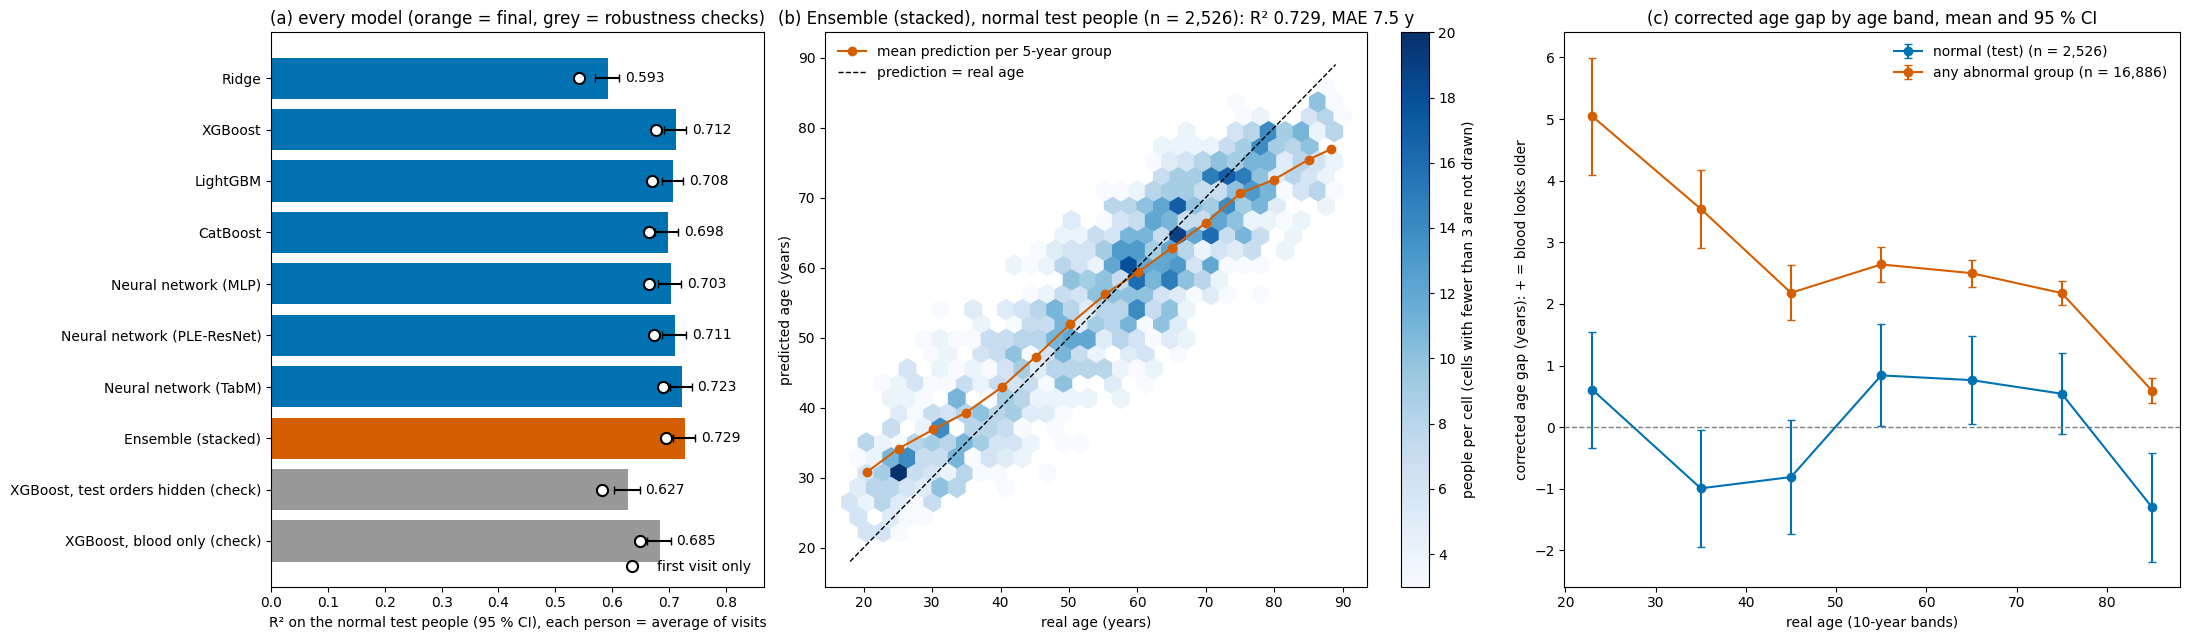

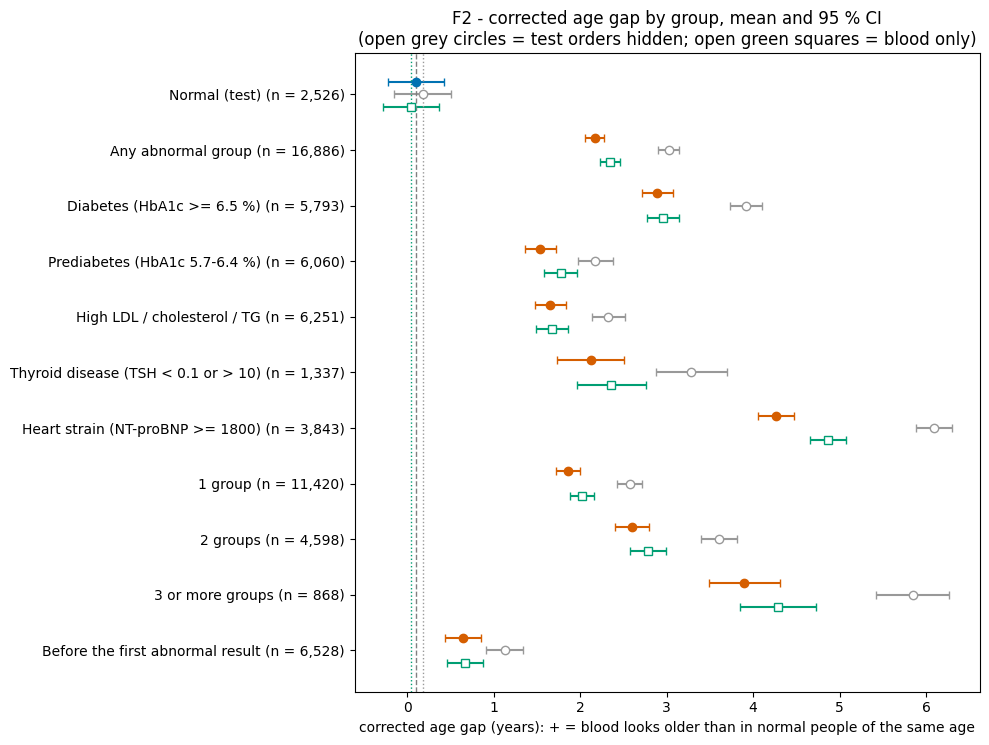

Saved in /kaggle/working/age_gap: F1_model_and_gap_by_age.png, F2_gap_by_group.png, T1_dataset.csv, T3_cohort.csv, T4_inputs.csv, T5_models_validation.csv, T6_test_normal.csv, T8_age_gap_by_group.csv. Whole run: 303.7 min.


In [10]:
# ═════ 10 · FIGURES AND FILES ════════════════════════════════════════════════════════════════════════════════════
# F1 (a) R2 of every model on the normal test people, with its 95 % interval (white dot = first visit only); (b) the
#        final model on the normal test people: predicted against real age (shaded cells count >= 3 people; the line =
#        mean prediction per 5-year age group; the dashed line = a perfect model); (c) mean corrected gap per 10-year age
#        band: normal test people against compared people in any abnormal group.
# F2 the mean corrected age gap of every group with its 95 % interval (normal test people in blue); open markers = the
#    robustness checks (grey circles: test orders hidden; green squares: blood only, without the body measurements).
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(22, 6.5), gridspec_kw={"width_ratios": [0.8, 1.1, 1]})
names_m = [n for n in TEST_PRED if n != "mean age (yardstick)"][::-1]
r2_m = [scores(y_te, TEST_PRED[n])["R2"] for n in names_m]
ax[0].barh(names_m, r2_m, xerr=np.array([[r - CI[n]["R2"][0], CI[n]["R2"][1] - r] for n, r in zip(names_m, r2_m)]).T,
           color=["#D55E00" if n == FINAL else "#999999" if n in CHECKS else "#0072B2" for n in names_m], capsize=3)
top_ci = [CI[n]["R2"][1] for n in names_m]
if PER_PERSON:                                                           # the same models judged on first visits only
    ax[0].plot([FIRST_R2[n] for n in names_m], range(len(names_m)), "o", mfc="white", mec="black", ms=8, mew=1.5,
               label="first visit only")
    ax[0].legend(loc="lower right", frameon=False)
for i_, (r, hi_) in enumerate(zip(r2_m, top_ci)):
    ax[0].text(max(hi_, r) + 0.01, i_, f"{r:.3f}", va="center", ha="left")
ax[0].set(xlabel="R² on the normal test people (95 % CI)" + (", each person = average of visits" if PER_PERSON else ""),
          xlim=(min(0.0, min(r2_m) - 0.05), max(0.1, max(top_ci)) + 0.12),
          title="(a) every model (orange = final, grey = robustness checks)")
hb = ax[1].hexbin(y_te, P_TE, gridsize=30, mincnt=3, cmap="Blues", extent=(AGE_MIN, AGE_MAX + 1, AGE_MIN, AGE_MAX + 1))
fig.colorbar(hb, ax=ax[1], label="people per cell (cells with fewer than 3 are not drawn)")
bins5 = pd.cut(pd.Series(y_te), np.arange(AGE_MIN, AGE_MAX + 6, 5), right=False)
m5 = pd.DataFrame({"real": y_te, "pred": P_TE}).groupby(bins5, observed=True).agg(real=("real", "mean"), pred=("pred", "mean"),
                                                                                   n=("pred", "size"))
m5 = m5.loc[m5.n >= 10]
ax[1].plot(m5.real, m5.pred, "o-", color="#D55E00", label="mean prediction per 5-year group")
ax[1].plot([AGE_MIN, AGE_MAX], [AGE_MIN, AGE_MAX], "k--", lw=1, label="prediction = real age")
s_te = scores(y_te, P_TE)
ax[1].set(xlabel="real age (years)", ylabel="predicted age (years)",
          title=f"(b) {FINAL}, normal test people (n = {len(y_te):,}): R² {s_te['R2']:.3f}, MAE {s_te['MAE']:.1f} y")
ax[1].legend(loc="upper left", frameon=False)
bands = [18, 30, 40, 50, 60, 70, 80, 90]
for label, frame, color in [("normal (test)", REF, "#0072B2"), ("any abnormal group", abn, "#D55E00")]:
    g_ = frame.groupby(pd.cut(frame.age, bands, right=False), observed=True).gap.agg(["mean", "std", "size"])
    g_ = g_.loc[g_["size"] >= 20]
    ax[2].errorbar([iv.left + 5 for iv in g_.index], g_["mean"], yerr=1.96 * g_["std"] / np.sqrt(g_["size"]), fmt="o-",
                   color=color, capsize=3, label=f"{label} (n = {len(frame):,})")
ax[2].axhline(0, color="grey", ls="--", lw=1)
ax[2].set(xlabel="real age (10-year bands)", ylabel="corrected age gap (years): + = blood looks older",
          title="(c) corrected age gap by age band, mean and 95 % CI")
ax[2].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "F1_model_and_gap_by_age.png", dpi=130, bbox_inches="tight")
display(fig)
plt.close(fig)

names_ = list(GAPS)
fig2, ax2 = plt.subplots(figsize=(10, 0.55 * len(names_) + 1.5))
ypos = np.arange(len(names_))[::-1]
CHECK_STYLE = {"test orders hidden": dict(fmt="o", color="#999999", mfc="white", name="open grey circles"),
               "blood only": dict(fmt="s", color="#009E73", mfc="white", name="open green squares")}
series = [(GAPS, None)] + [(gaps_c, short_c) for short_c, gaps_c in GAPS_CHECKS.items()]
offsets = [0.12, -0.18] if len(series) == 2 else list(np.linspace(0.22, -0.22, len(series))) if len(series) > 2 else [0.0]
for y_, n_ in zip(ypos, names_):
    for (gaps_, short_c), dy in zip(series, offsets):
        style = (dict(fmt="o", color="#0072B2" if n_ == "Normal (test)" else "#D55E00") if short_c is None
                 else {k_: v_ for k_, v_ in CHECK_STYLE.get(short_c, dict(fmt="o", color="#999999", mfc="white")).items()
                       if k_ != "name"})
        if n_ in gaps_:
            g = gaps_[n_]
            half = stats.t.ppf(0.975, len(g) - 1) * g.std(ddof=1) / np.sqrt(len(g))
            ax2.errorbar(g.mean(), y_ + dy, xerr=half, capsize=3, **style)
ax2.axvline(GAPS["Normal (test)"].mean(), color="grey", ls="--", lw=1)
for short_c, gaps_c in GAPS_CHECKS.items():                       # each check's own normal reference
    ax2.axvline(gaps_c["Normal (test)"].mean(), color=CHECK_STYLE.get(short_c, {}).get("color", "#BBBBBB"), ls=":", lw=1)
ax2.set_yticks(ypos, [f"{n_} (n = {len(GAPS[n_]):,})" for n_ in names_])
ax2.set(xlabel="corrected age gap (years): + = blood looks older than in normal people of the same age",
        title="F2 - corrected age gap by group, mean and 95 % CI"
        + ("\n(" + "; ".join(f"{CHECK_STYLE.get(s_, {}).get('name', 'open markers')} = {s_}" for s_ in GAPS_CHECKS) + ")"
           if GAPS_CHECKS else ""))
fig2.tight_layout()
fig2.savefig(OUT / "F2_gap_by_group.png", dpi=130, bbox_inches="tight")
display(fig2)
plt.close(fig2)

T_DATA.to_csv(OUT / "T1_dataset.csv", index=False)
T_FEAT.to_csv(OUT / "T4_inputs.csv", index=False)
T_COHORT.to_csv(OUT / "T3_cohort.csv", index=False)
T_MODELS.to_csv(OUT / "T5_models_validation.csv", index=False)
if len(T_CHOICE):
    T_CHOICE.to_csv(OUT / "T5a_data_choices.csv", index=False)
T_TEST.to_csv(OUT / "T6_test_normal.csv", index=False)
T_GAP.to_csv(OUT / "T8_age_gap_by_group.csv", index=False)
con.close()
print(f"Saved in {OUT}: F1_model_and_gap_by_age.png, F2_gap_by_group.png, T1_dataset.csv, T3_cohort.csv, T4_inputs.csv, "
      f"T5_models_validation.csv, T6_test_normal.csv, T8_age_gap_by_group.csv. Whole run: {(time.time() - T0) / 60:.1f} min.")